# keff tuning from the track-level rDCA offset and the K0s: study of the real re-reco scans

Convention: every keff is given as **keff_new / keff_CDB** (factor on the CDB base keff; the GEM-current factor is applied on top by the reco).

Data (all cached in `ml/newgain/v0keffscan/`):
* **O+O (run3oo):** 67 runs, real re-reco at ×0.95, 1.05, 1.15, 1.25 of the CDB keff with the MLP space-charge map (`sc50`); track-level rDCA offset and ln(N+/N−) for 37 of them at the first three points.
* **pp (run3pp):** 24 runs, same map, ×0.95, 1.05, 1.15 (and ×1.25 for 8 runs).
* K0s: adopted selection (section S): sailor cut, K0s pT 0.5–3 GeV, decay length Lxy > 5 cm; width σ = Gaussian + linear fit in 1 MeV bins; **same segments and same events at every keff point**.

Sections: S K0s selection · A track-level observables (O+O) · C all K0s mass peaks · D width vs keff with errors · E significance and yield · F correlations with the observables · **G robust rDCA vs K0s and the recalibrated recipe (leave-one-out)** · G2 pp side by side · G3 pp rDCA input check (81556) · G4 charge balance, combinations, robustness · H recipe.

In [1]:
import os; os.environ['KSEL_SUF'] = 'n'      # adopted K0s selection: pT 0.5-3 GeV, Lxy > 5 cm (set '' for the original pT 0.5-1.2 selection)
import sys, pickle
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
T = Path('/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking'); sys.path.insert(0, str(T/'ml/newgain/v0keffscan'))
import kscan5_plot as K5, kscan5_corr as KC, keffstudy_plots as KP
plt.rcParams.update({'font.size': 13, 'axes.grid': True, 'grid.alpha': .3, 'figure.dpi': 80})
G, Ro = KC.feats(); D, Rall, Rm = KP.obs_tables()
pp, oo = K5.load('pp'), K5.load('oo'); zpp, zoo = pickle.load(open(KP.V + 'signif%s_pp.pkl' % K5.SUF, 'rb')), pickle.load(open(KP.V + 'signif%s_oo.pkl' % K5.SUF, 'rb')); ypp, yoo = K5.loady('pp'), K5.loady('oo')
Opp, Ooo = KC.optima('pp'), KC.optima('oo'); print(len(oo), 'O+O runs,', len(pp), 'pp runs in the K0s scans;', Rm.shape[0], 'O+O runs with track-level observables')

67 O+O runs, 24 pp runs in the K0s scans; 36 O+O runs with track-level observables


## S. K0s selection

The original K0s sample used daughters' pair pT 0.5–1.2 GeV. A study of 12 selections on the 24 pp runs (error on the optimum from a paired bootstrap over segments; correlation with the two predictors; leave-one-out rms) showed that pT ≥ 1 GeV or a decay-length cut improve the error and the correlation in pp, but pT 1.0–3 GeV does **not** hold in O+O (error 0.09 against 0.05, no correlation). The selection that works in both systems is **all pT (0.5–3 GeV) with Lxy > 5 cm**: in pp r(balance) = +0.89 with leave-one-out rms 0.021 against 0.041 for a constant, in O+O r(rDCA) = −0.54 with rms 0.037 against 0.044. It is **adopted for everything below** (width, significance, yield, mass peaks); the original selection can be restored by setting `KSEL_SUF = ''` in the first cell. Heavy tightening (DIRA > 0.99 or a tight combination) loses 70–85 % of the candidates and is worse.

In [2]:
for nm in ('pp', 'oo'):
    print({'pp': 'pp, 24 runs', 'oo': 'O+O, 36 runs with predictors'}[nm] + ': error on the width optimum, correlation and leave-one-out rms for each selection (balance and rDCA predictors; const = constant)')
    display(pd.read_csv(KP.V + 'cuts_study_%s.csv' % nm, index_col=0).round(3))

pp, 24 runs: error on the width optimum, correlation and leave-one-out rms for each selection (balance and rDCA predictors; const = constant)


,n_per_run,sigma_MeV,sens_per_unit_f,err_fopt,edge_frac,r_rDCA,r_bal,loo_rDCA,loo_bal,const
config,,,,,,,,,,
all + Lxy>5,25429.125,8.482,0.570,0.015,0.25,-0.709,0.891,0.031,0.021,0.041
all + Lxy>5 + qT<0.22,24359.958,9.500,0.574,0.014,0.25,-0.729,0.904,0.031,0.020,0.041
all + Lxy>5 + qT<0.22 + pairDCA<1,23594.042,9.443,0.560,0.012,0.25,-0.739,0.906,0.031,0.020,0.042


O+O, 36 runs with predictors: error on the width optimum, correlation and leave-one-out rms for each selection (balance and rDCA predictors; const = constant)


,n_per_run,sigma_MeV,sens_per_unit_f,err_fopt,edge_frac,r_rDCA,r_bal,loo_rDCA,loo_bal,const
config,,,,,,,,,,
base 0.5-1.2,10625.750,8.397,0.817,0.048,0.167,-0.032,0.322,0.065,0.060,0.060
pT 1.0-3,9552.250,10.479,0.831,0.089,0.167,0.166,-0.047,0.080,0.080,0.077
1.0-3 + Lxy>5,5571.750,9.926,1.021,0.062,0.139,0.026,0.057,0.069,0.067,0.064
all + Lxy>5,10450.625,8.748,0.781,0.049,0.111,-0.537,0.303,0.037,0.042,0.044
pT 1.2-3,7161.625,10.895,NaN,0.097,0.333,0.217,-0.261,0.097,0.095,0.093
1.0-3 + Lxy>4 + alpha<0.8,6248.375,10.131,0.674,0.074,0.222,0.005,0.041,0.073,0.071,0.067


## A. O+O: track-level observables versus keff

rDCA offset = shift of the tracks that flips sign with the charge (q+ minus q−), and ln(N+/N−), for every run and side as a function of the keff factor. The factor where the offset vanishes (the "rDCA zero crossing") is the keff the tracks want. Calibration: zero crossing against the offset measured in the CDB reco, which is available for any run without a scan.

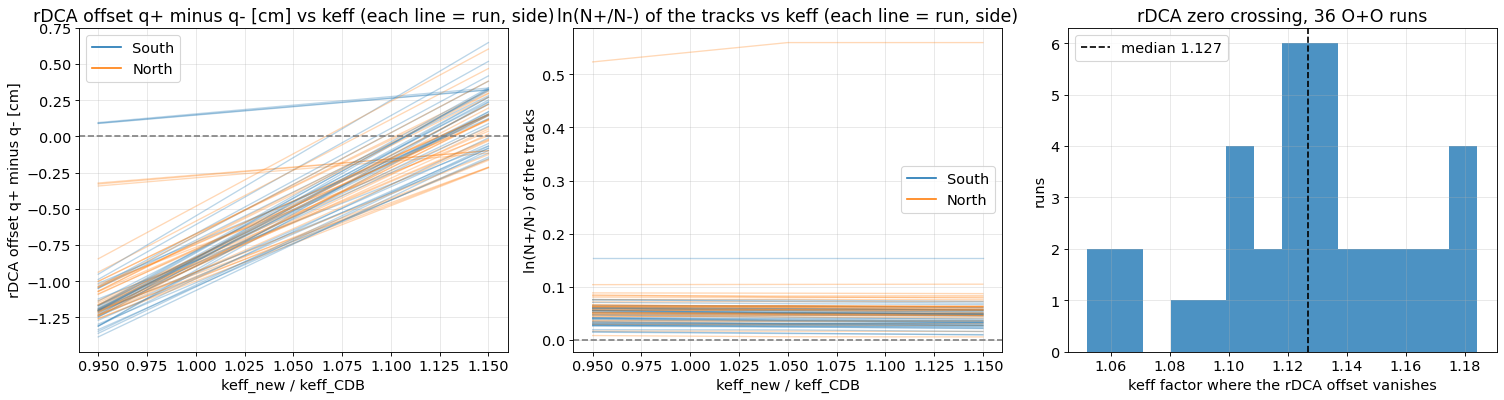

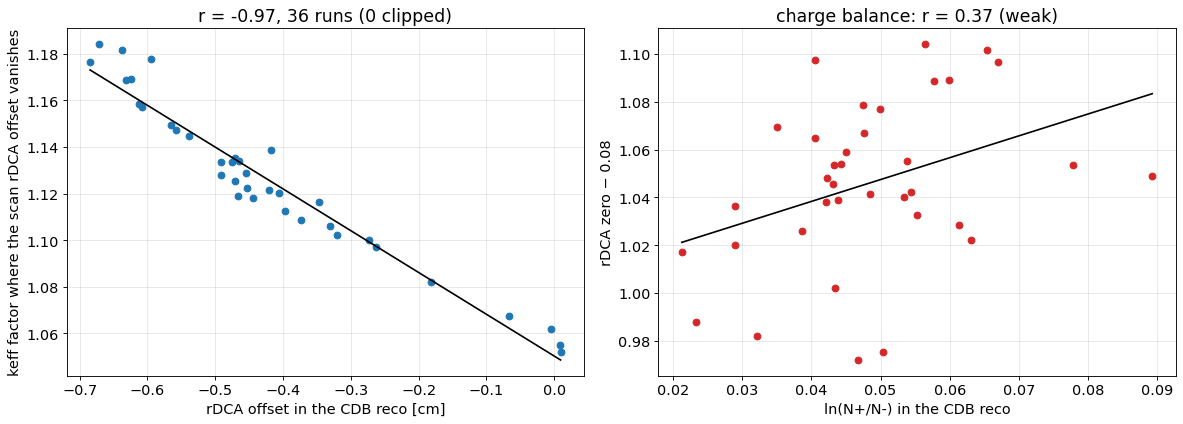

O+O: keff_new/keff_CDB (K0s optimum proxy = rDCA zero - 0.08) = 0.970 -0.179 * rDCA_offset_CDB[cm];  from ln(N+/N-): 1.002 +0.91 * ln(N+/N-) (weak)


In [3]:
KP.fig_rdca_scan(D, Rm); plt.show()
fig, bo, bl = KP.fig_calib(Rm); plt.show()
print('O+O: keff_new/keff_CDB (K0s optimum proxy = rDCA zero - 0.08) = %.3f %+.3f * rDCA_offset_CDB[cm];  from ln(N+/N-): %.3f %+.2f * ln(N+/N-) (weak)' % (bo[1], bo[0], bl[1], bl[0]))

## C. K0s mass peaks, every run and keff point

Mass minus PDG for the adopted selection (K0s pT 0.5–3 GeV, decay length Lxy > 5 cm, sailor cut; histograms normalised to 100 % of the candidates in ±60 MeV, so the points with fewer events are comparable); curves = Gaussian + linear fit, legend gives σ and the fitted mean shift. Colours: ×0.95 blue, ×1.05 green, ×1.15 orange, ×1.25 red.

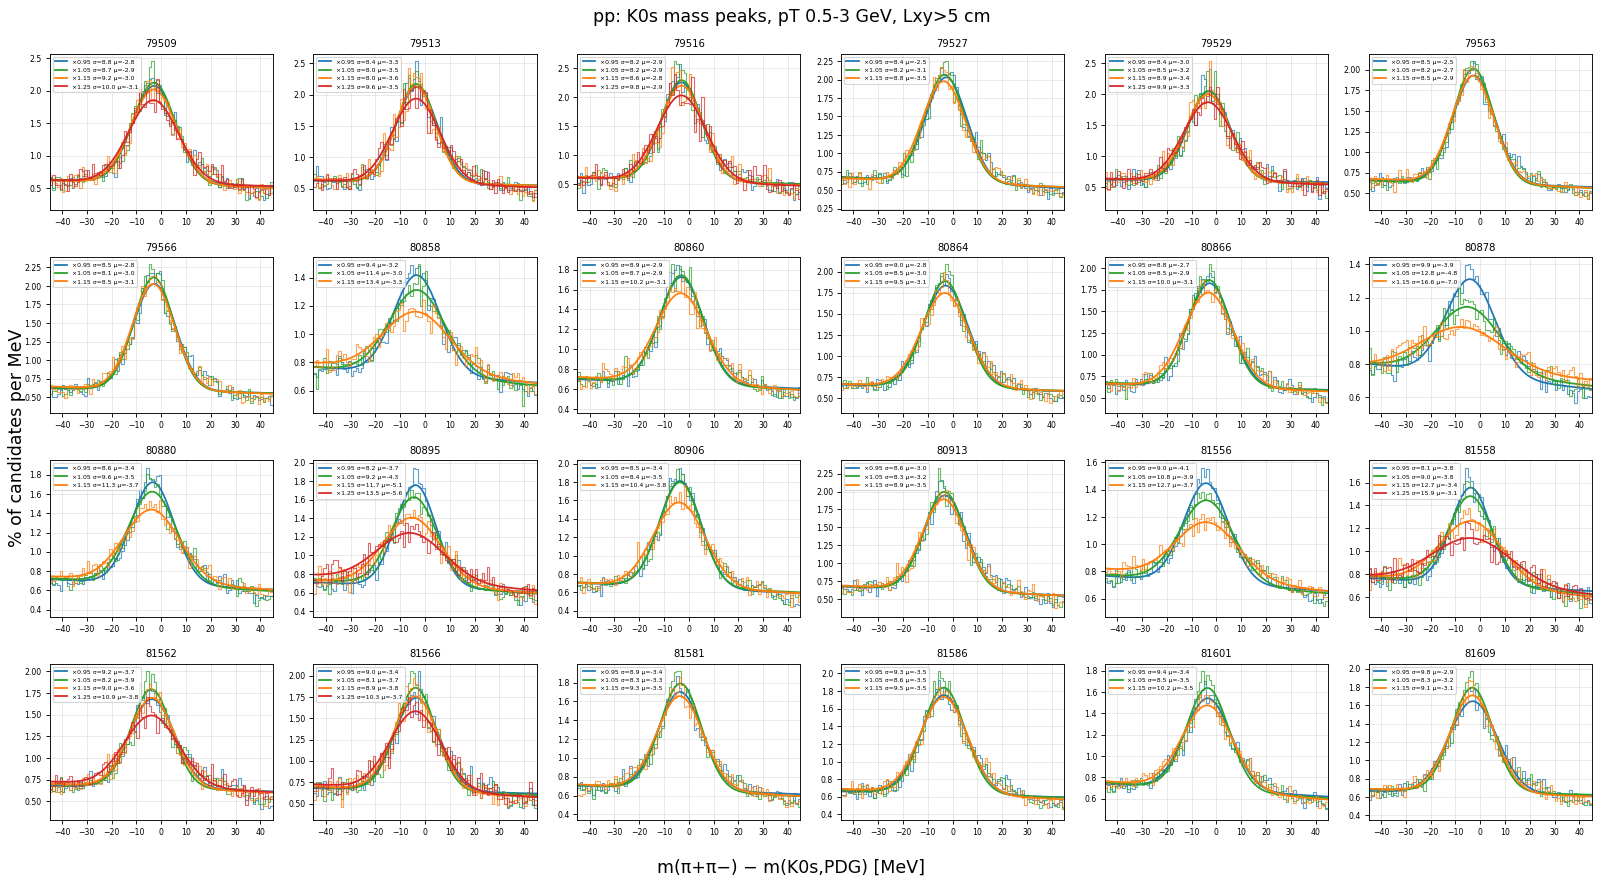

In [4]:
dpp = np.load(KP.V + 'hist_cache%s_pp.npz' % K5.SUF); KP.fig_mass('pp', [int(r) for r in dpp['runs']], title='pp: K0s mass peaks, ' + K5.SELTXT); plt.show()

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/ml/newgain/v0keffscan/keffstudy_plots.py:35: OptimizeWarning: Covariance of the parameters could not be estimated
  try: p, _ = curve_fit(f, c[k], h[k], p0=[h.max(), 0, 7, max(h.min(), .1), 0], maxfev=4000); return p, f


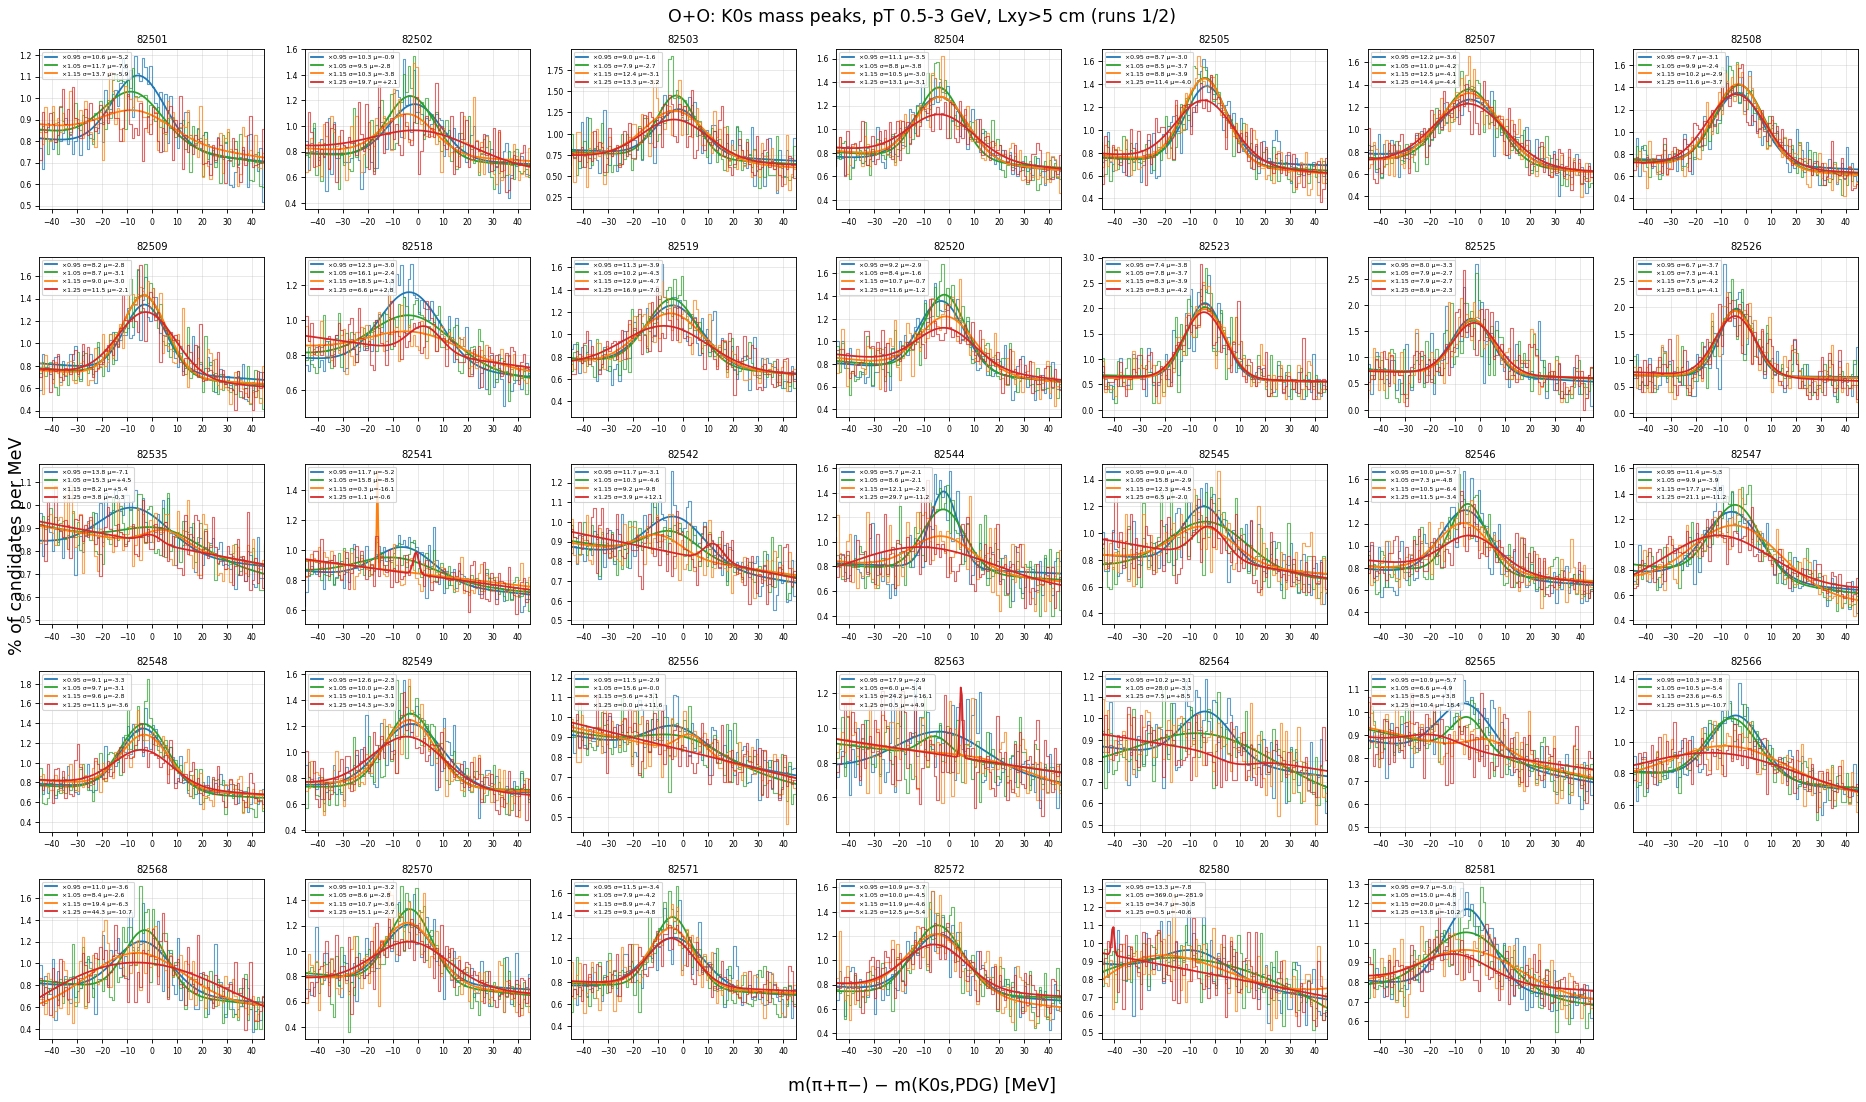

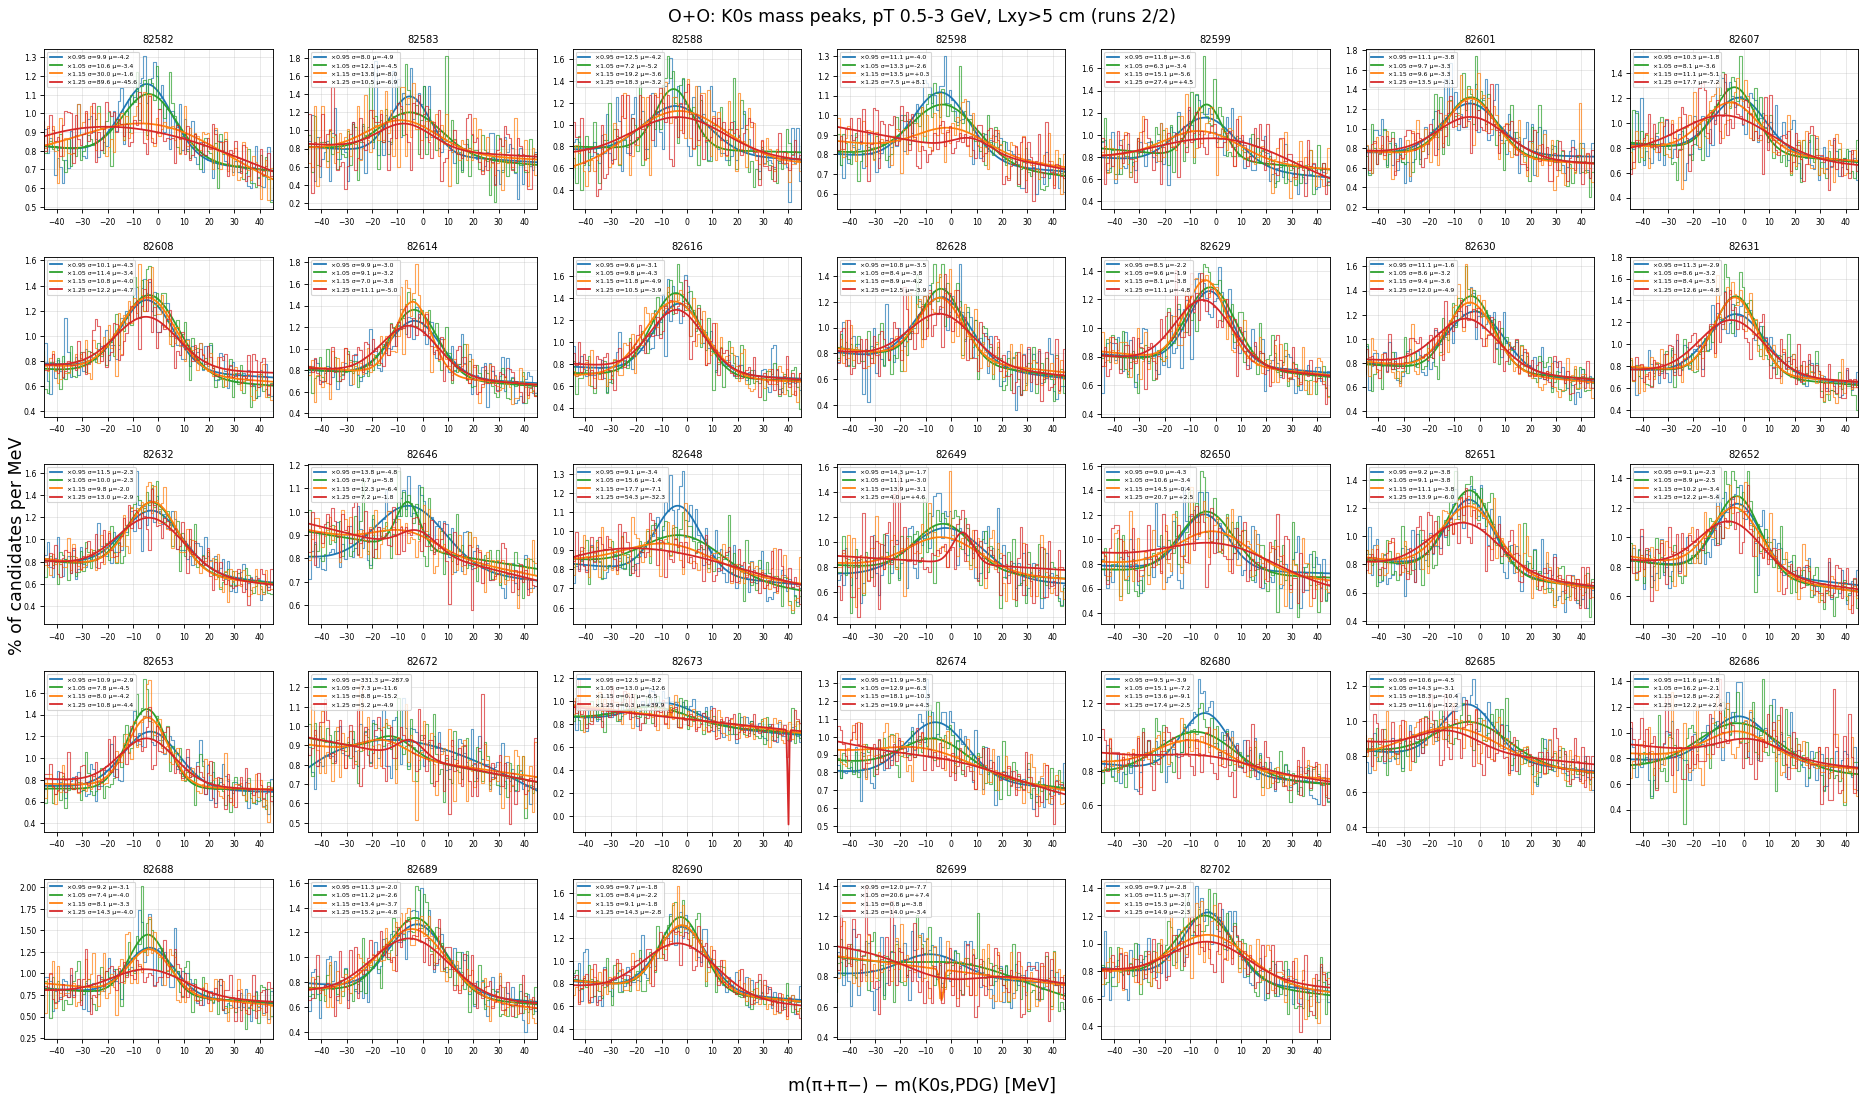

In [5]:
doo = np.load(KP.V + 'hist_cache%s_oo.npz' % K5.SUF); r_oo = [int(r) for r in doo['runs']]; h = (len(r_oo) + 1)//2
KP.fig_mass('oo', r_oo[:h], ncol=7, title='O+O: K0s mass peaks, ' + K5.SELTXT + ' (runs 1/2)'); plt.show()
KP.fig_mass('oo', r_oo[h:], ncol=7, title='O+O: K0s mass peaks, ' + K5.SELTXT + ' (runs 2/2)'); plt.show()

## D. K0s width versus keff, with errors

Adopted selection (K0s pT 0.5–3 GeV, Lxy > 5 cm). Statistical error: bootstrap over segments (same resample at all points, so correlated). Systematic error: spread over 18 fit variants (bin 0.5/1/2 MeV × fit range 35/45/60 MeV × linear/quadratic background). In pp the systematic spread of σ (median 0.85 MeV) is larger than the statistical one (0.34 MeV) but is almost the same shift at all points, so the optimum moves by only 0.007 (median); in O+O (fewer candidates per run) the two are comparable (σ: 2.0 vs 2.7 MeV; optimum: 0.06 vs 0.08). The optimum `f_opt` is the vertex of a parabola through σ(f); points at the 0.95 or 1.25 edge are marked: the true minimum is outside the scan.

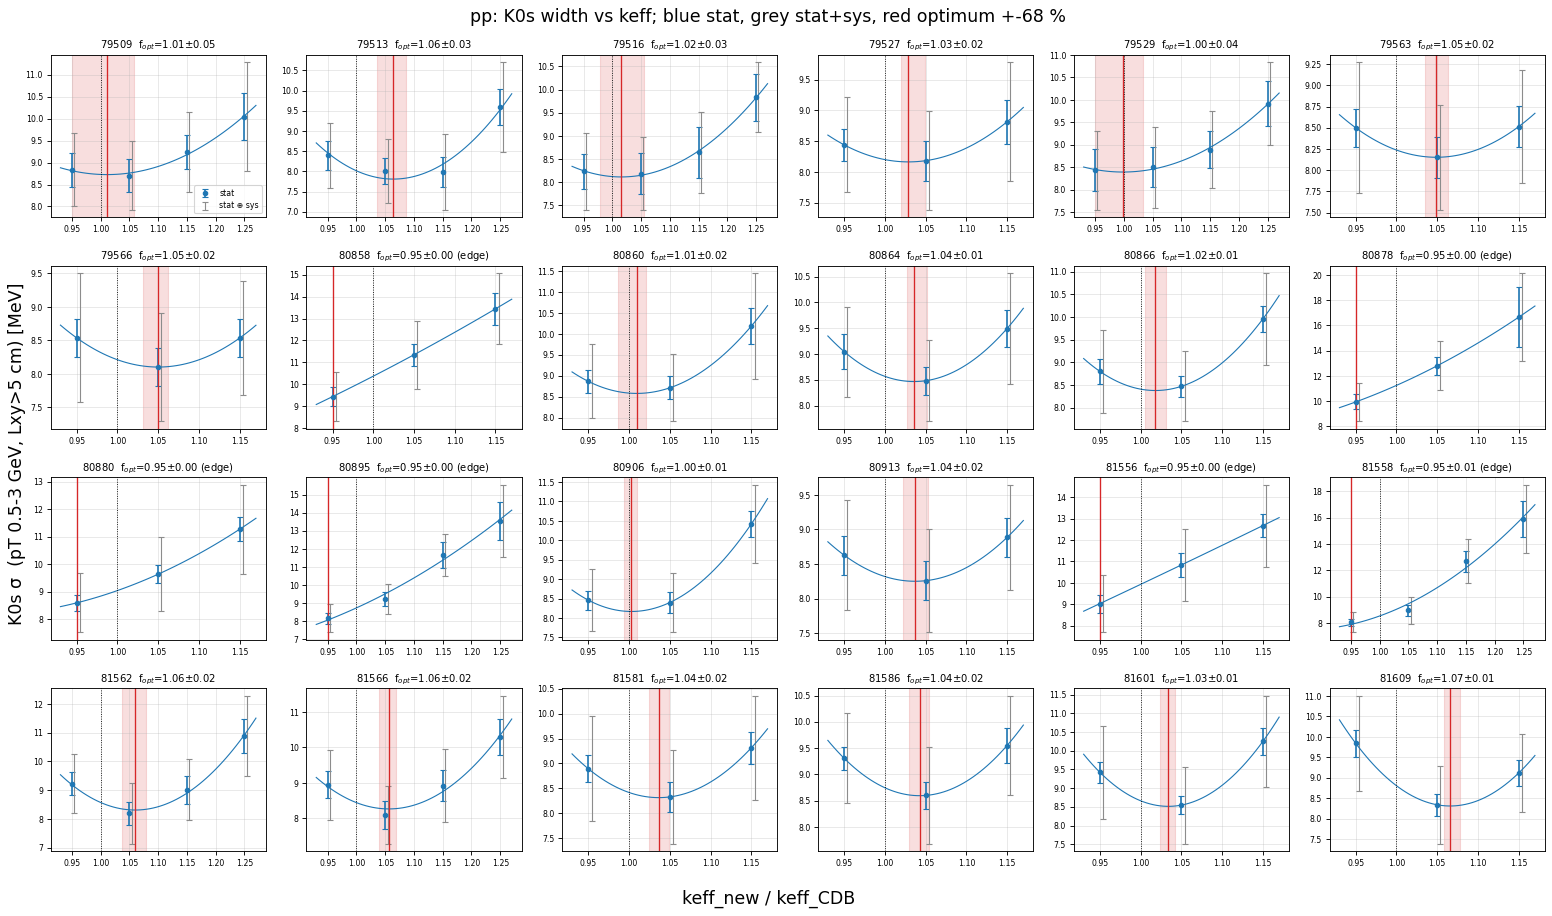

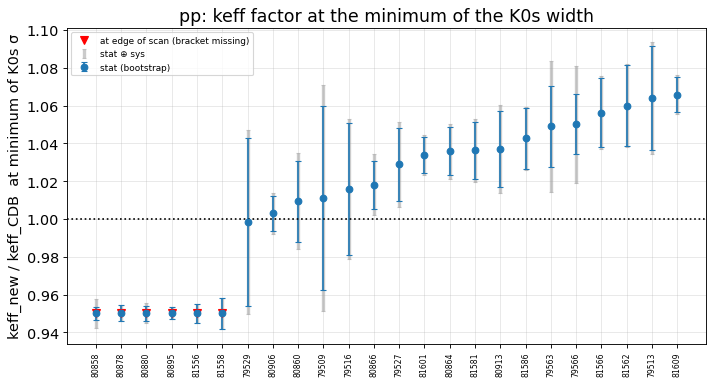

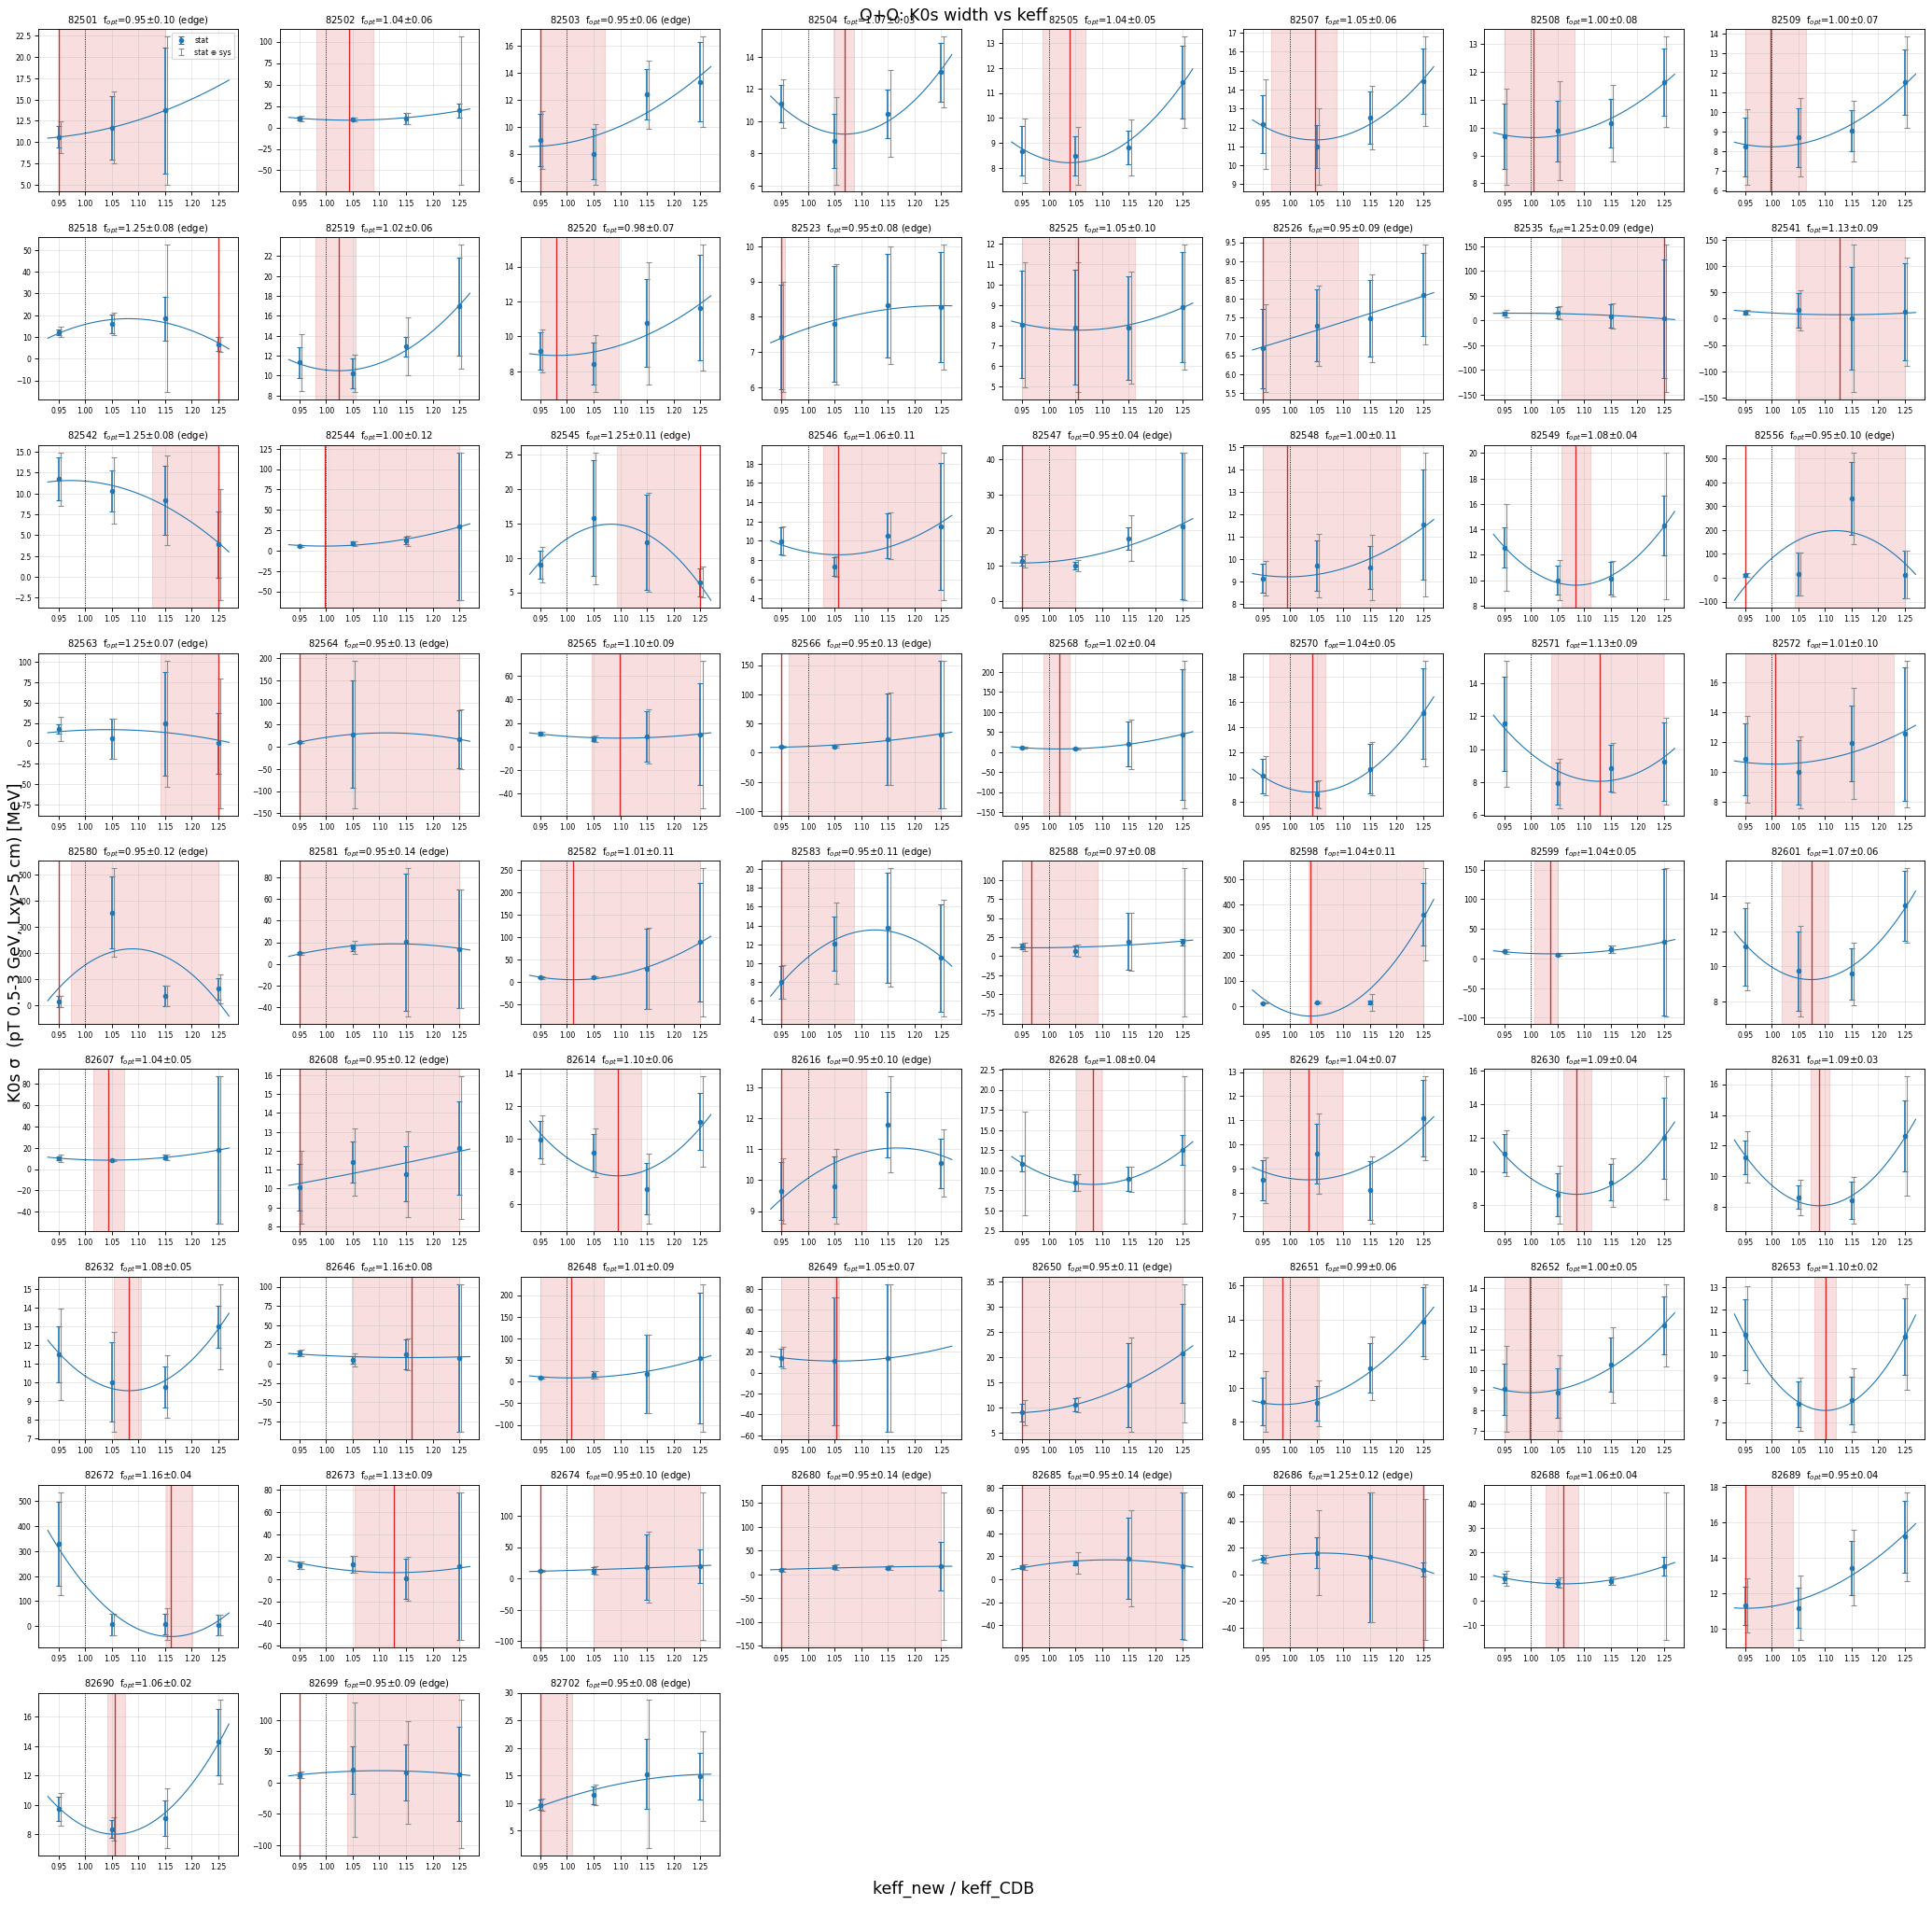

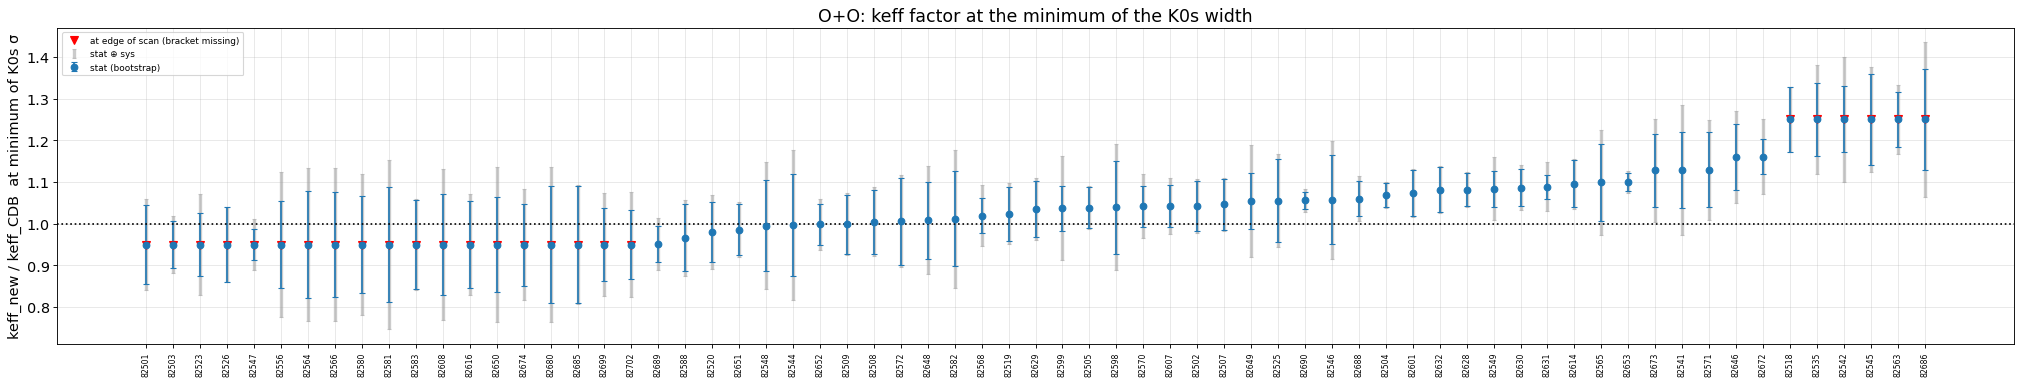

pp: f_opt median 1.024, 10-90 % 0.95-1.06, at an edge of the scan: 6 of 24
O+O: f_opt median 1.035, 10-90 % 0.95-1.16, at an edge of the scan: 25 of 67
79513: f_opt = 1.064 +- 0.027 (stat) +- 0.011 (sys), P(f_opt>1.10) = 0.02


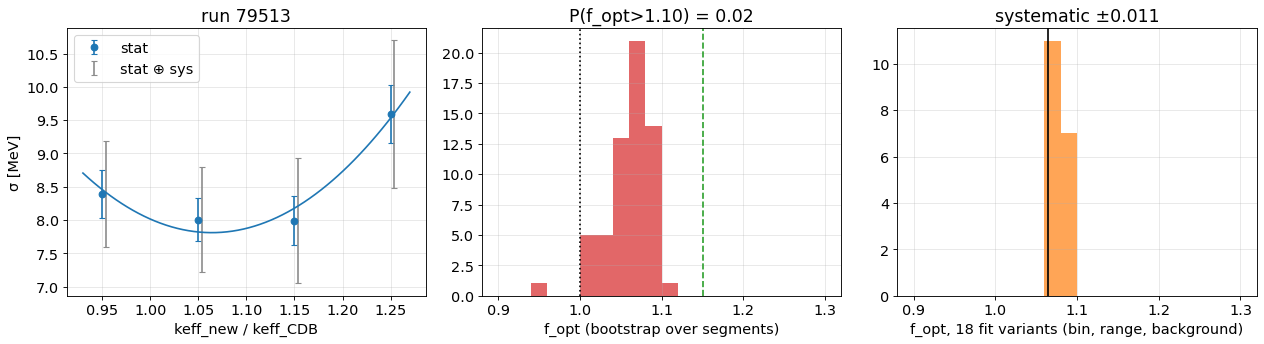

In [6]:
K5.fig_curves(pp, ncol=6, title='pp: K0s width vs keff; blue stat, grey stat+sys, red optimum +-68 %'); plt.show()
K5.fig_opt(pp, 'pp: keff factor at the minimum of the K0s width'); plt.show()
K5.fig_curves(oo, ncol=8, title='O+O: K0s width vs keff'); plt.show()
K5.fig_opt(oo, 'O+O: keff factor at the minimum of the K0s width'); plt.show()
for nm, rows in (('pp', pp), ('O+O', oo)):
    v = np.array([o['vopt'] for o in rows]); print('%s: f_opt median %.3f, 10-90 %% %.2f-%.2f, at an edge of the scan: %d of %d' % (nm, np.median(v), *np.percentile(v, [10, 90]), sum(o['edge'] for o in rows), len(rows)))
o = [o for o in pp if o['run'] == 79513][0]; print('79513: f_opt = %.3f +- %.3f (stat) +- %.3f (sys), P(f_opt>1.10) = %.2f' % (o['vopt'], o['vopt_stat'], o['vopt_sys'], o['frac_gt110'])); K5.fig_run(o); plt.show()

## E. Significance and yield

Significance Z = S/√(S+B), S and B the Gaussian and background integrals in a ±2σ window around the fitted peak (adopted selection). Unlike the yield it has an interior maximum for most runs. The K0s **yield** alone falls with keff in almost all runs (maximum at the lowest point in 24 of 24 pp and 64 of 67 O+O runs; median change to the last point −1.4 % in pp and −4.8 % in O+O), so it cannot give an optimum inside the scanned range; it is shown only as the median curve.

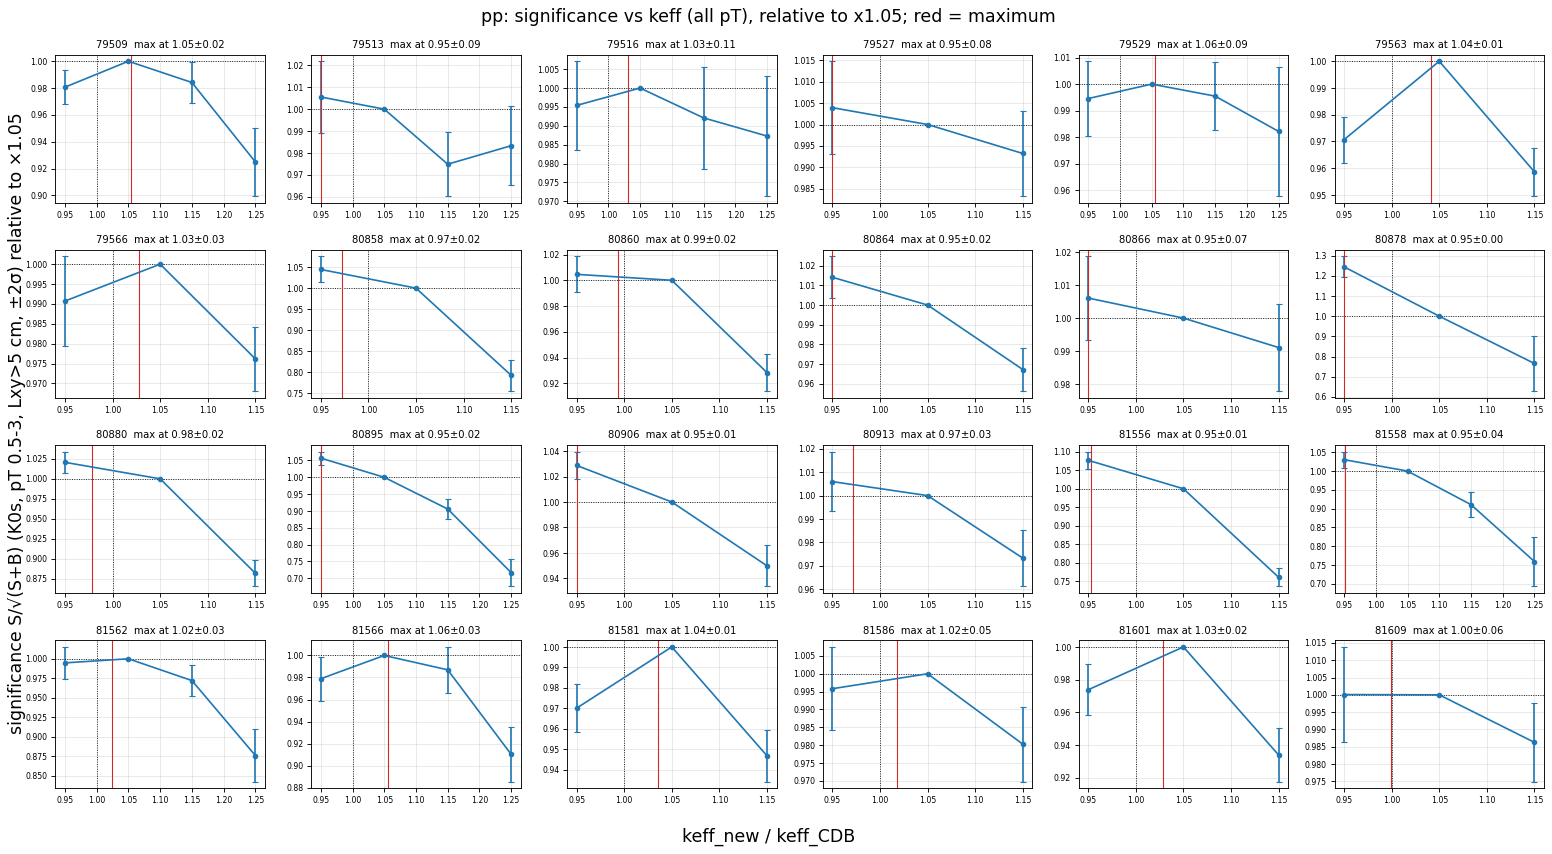

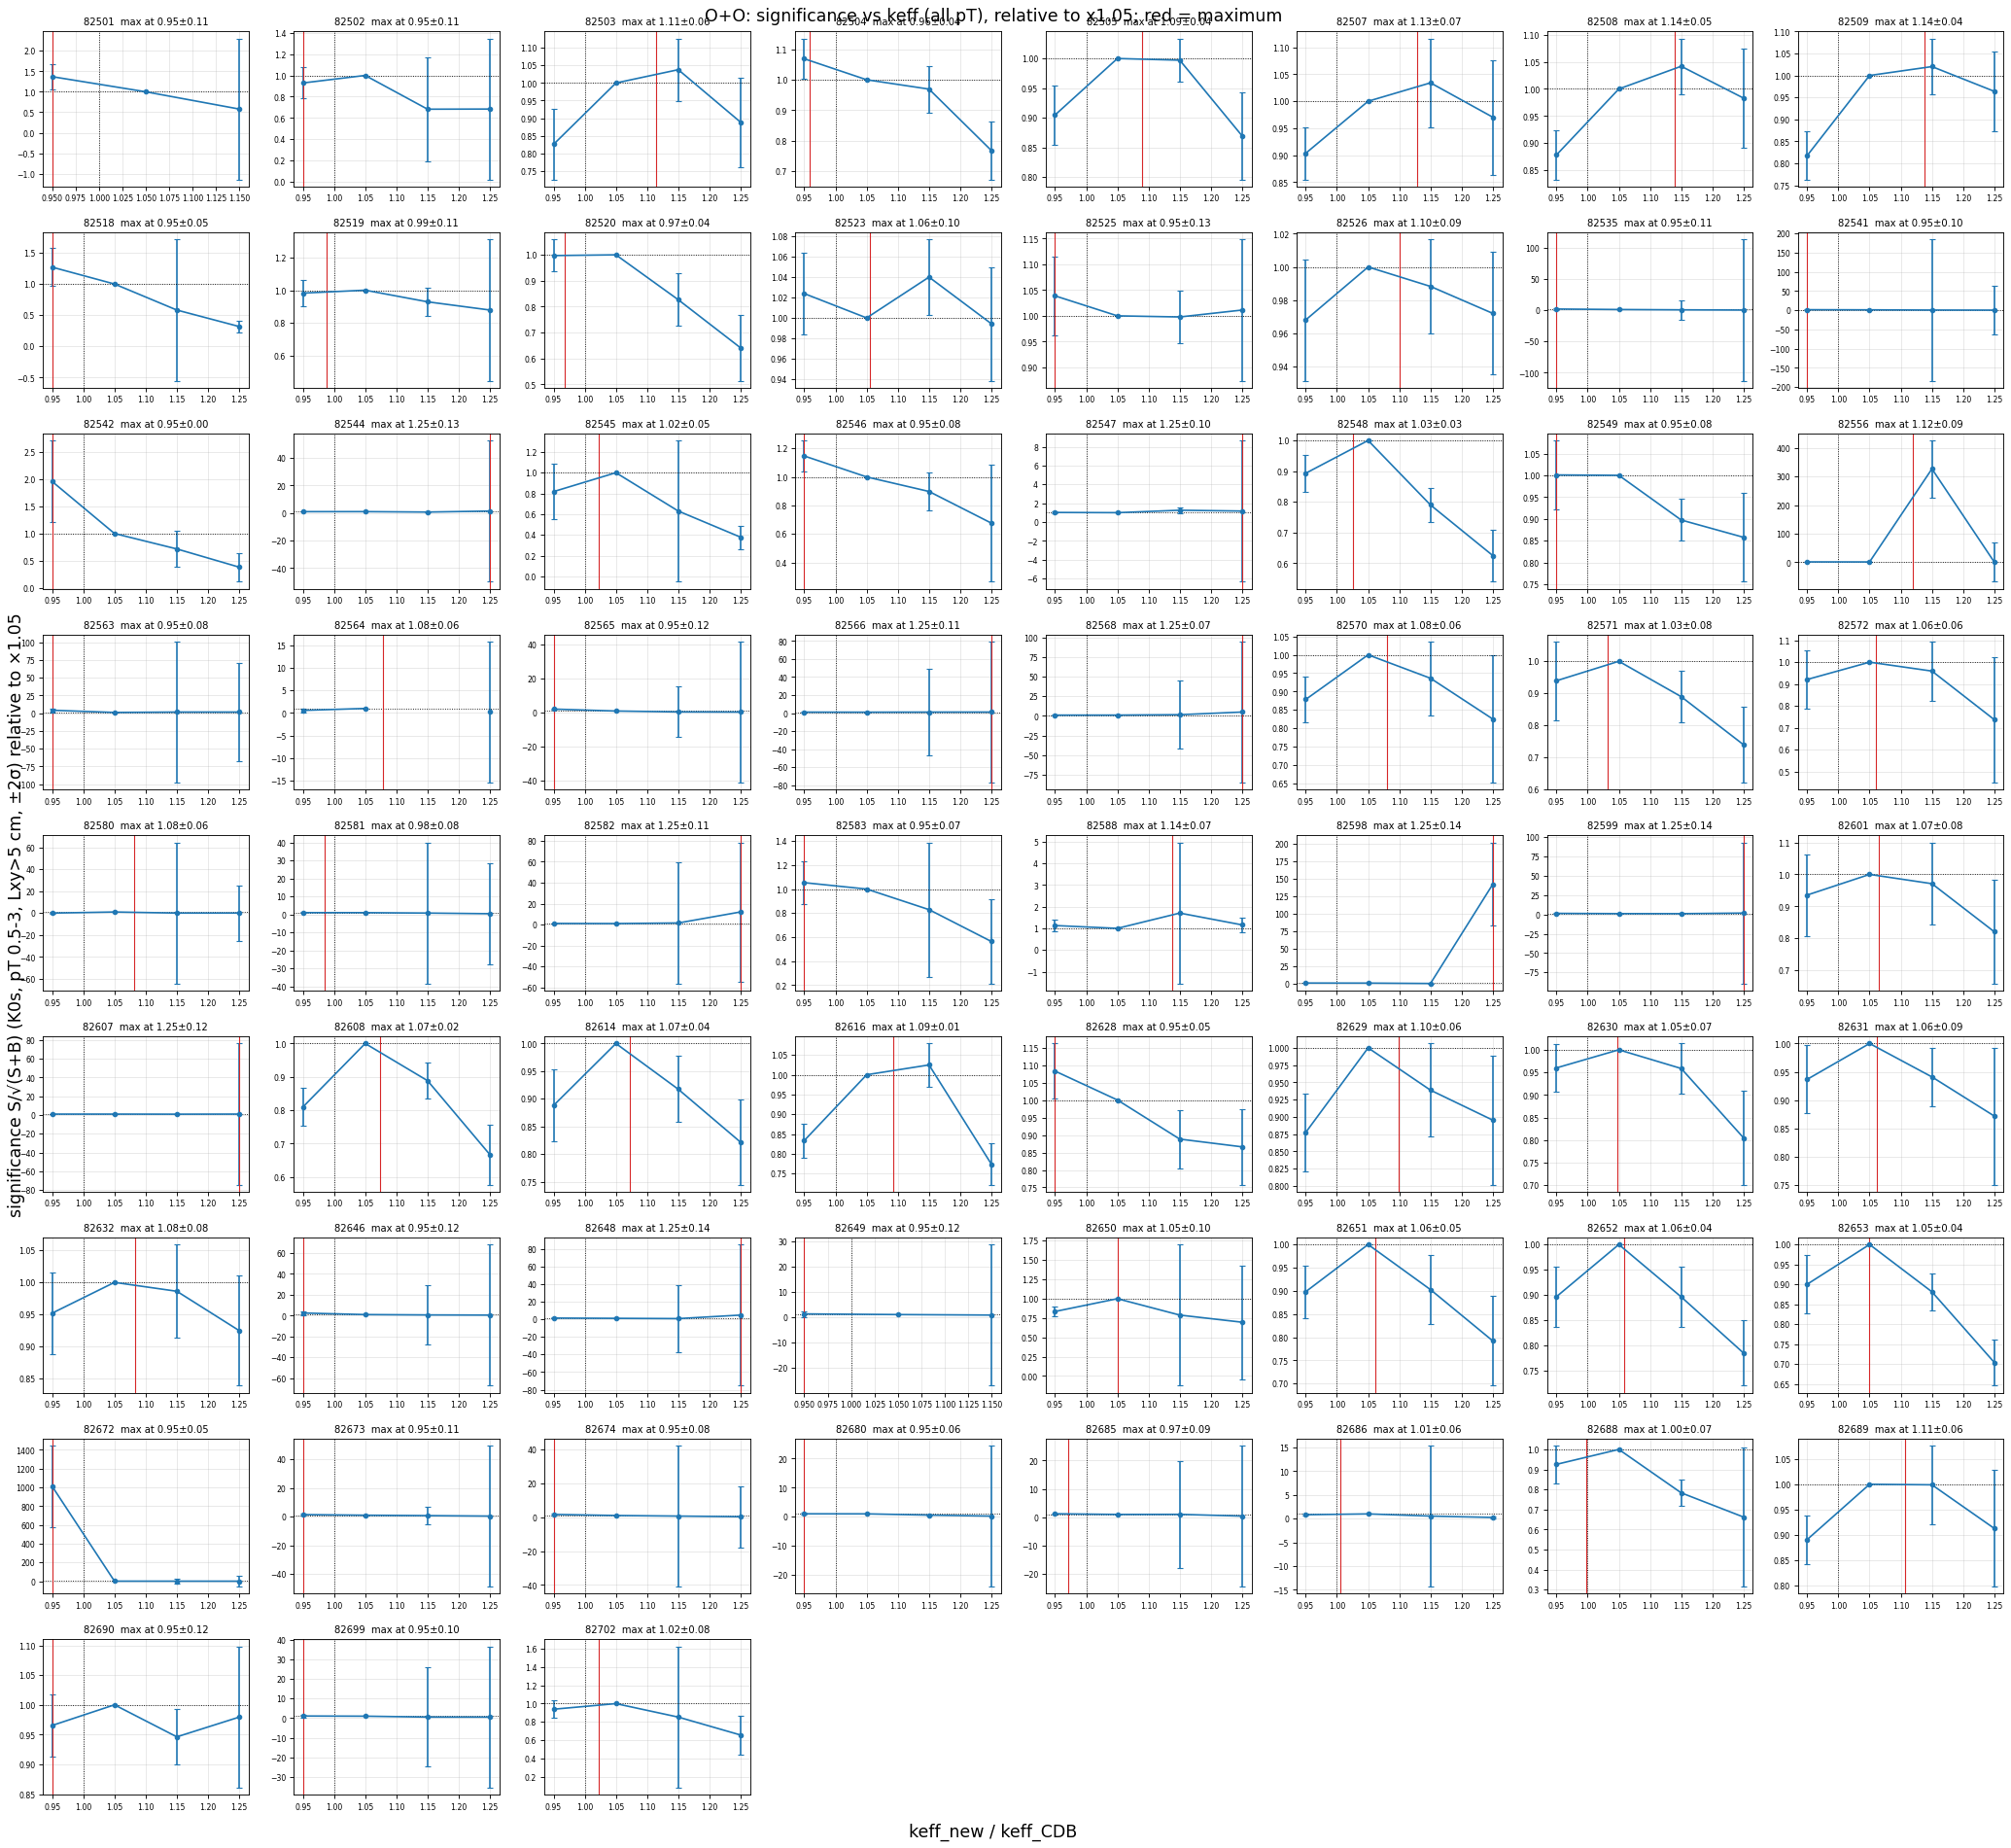

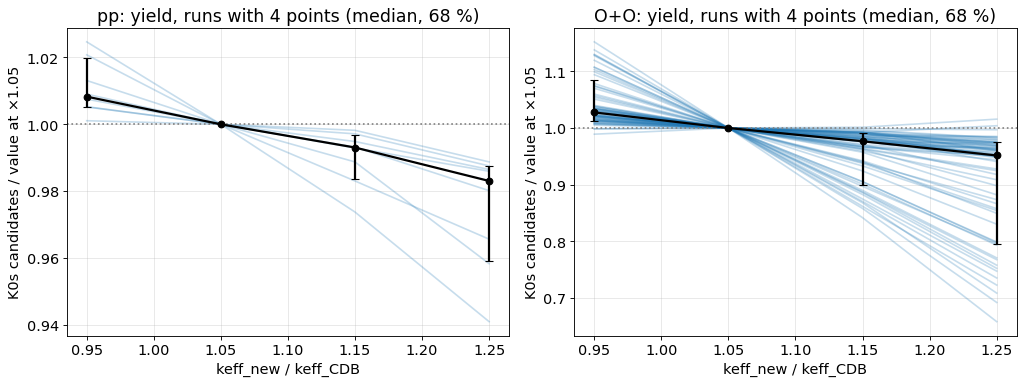

pp: significance maximum median 0.986, at an edge: 8 of 24
O+O: significance maximum median 1.049, at an edge: 30 of 67


In [7]:
KC.fig_zcurves(zpp, ncol=6, title='pp: significance vs keff (all pT), relative to x1.05; red = maximum'); plt.show()
KC.fig_zcurves(zoo, ncol=8, title='O+O: significance vs keff (all pT), relative to x1.05; red = maximum'); plt.show()
KP.fig_yield_mean(ypp, yoo); plt.show()
for nm, rows in (('pp', zpp), ('O+O', zoo)):
    v = np.array([o['zmax'][2] for o in rows]); print('%s: significance maximum median %.3f, at an edge: %d of %d' % (nm, np.median(v), ((v < .951) | (v > 1.249)).sum(), len(rows)))

## F. Do the observables of the CDB reco predict the K0s optimum?

For every run: x = observable measured in the CDB reco (available without a scan), y = K0s optimum from the scan (width, significance), error bars = bootstrap. In pp the per-run error of the optimum (median 0.018 on the combined target) is smaller than the spread of the optima (0.034), so correlations are visible. In O+O the error (median 0.046) is larger than the spread (0.039 around a constant), so correlations are diluted and the slope with its error is the number to read. The first figure tests directly whether the K0s optimum follows the rDCA zero crossing.

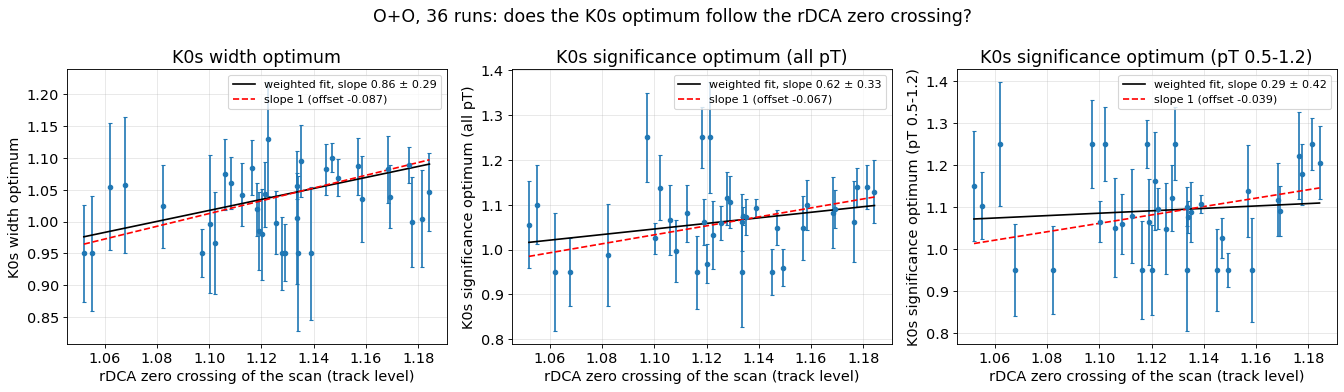

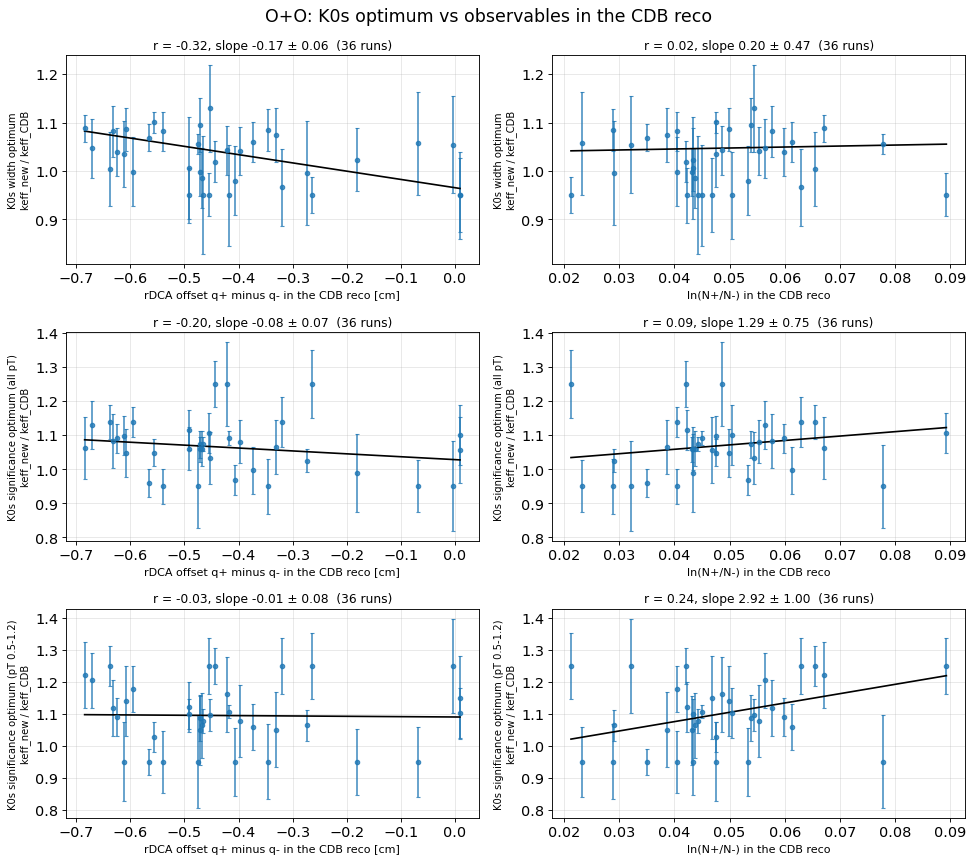

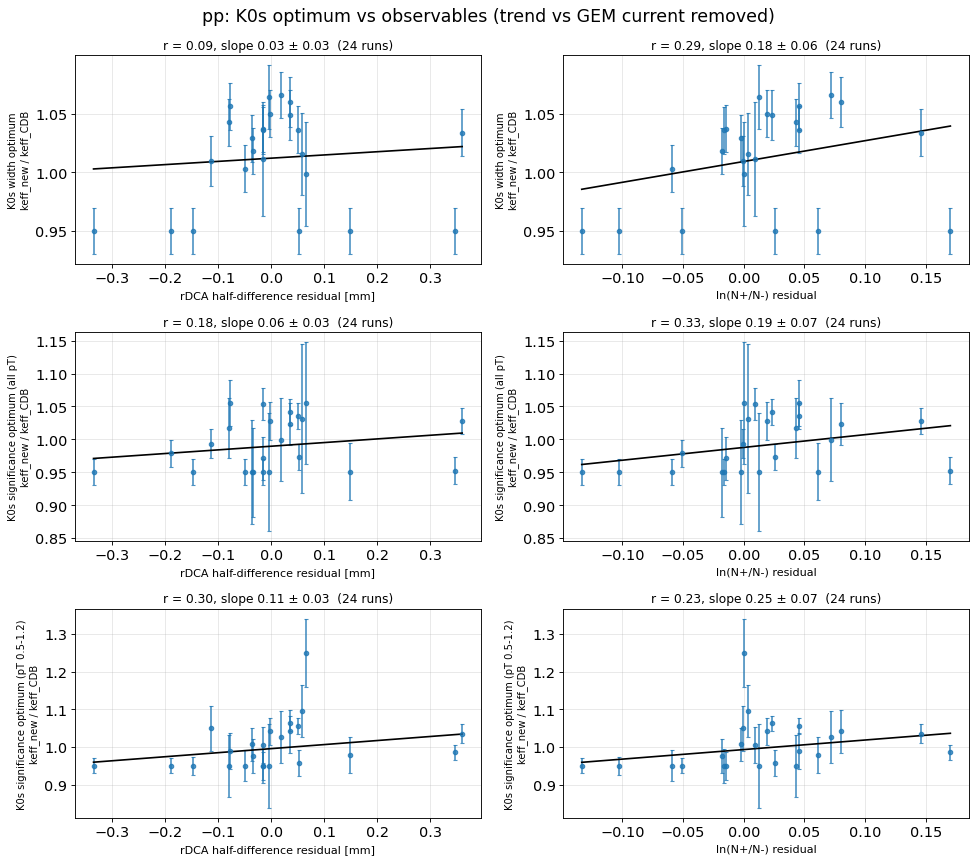

In [8]:
KC.fig_f0test(Ro); plt.show()
KC.fig_corr('oo', Ro, ('odd0_cdb', 'lnr_cdb'), ('rDCA offset q+ minus q- in the CDB reco [cm]', 'ln(N+/N-) in the CDB reco'), 'O+O: K0s optimum vs observables in the CDB reco'); plt.show()
KC.fig_corr('pp', G, ('rd_rI', 'lnr_rI'), ('rDCA half-difference residual [mm]', 'ln(N+/N-) residual'), 'pp: K0s optimum vs observables (trend vs GEM current removed)'); plt.show()

## G. Robust rDCA versus the K0s optimum, and the recalibrated recipe (leave-one-out)

**Robust rDCA.** Same definition as the O+O observable: for each charge, fit c + a·cos φ + b·sin φ with iterated 2.5σ MAD clipping, take the constant c, and form q+ minus q−. For O+O it comes from the tracks (rDCA_zero, CDB reco); for pp it is built from the QA φ-profiles of the mean rDCA of positive and negative tracks (valid bins only; error = bootstrap over φ bins). It replaces the value of the harmonic fit at φ=0, which fails at high current (section G3).

**Recipe.** Target = measured K0s optimum of each run (mean of the width minimum and the significance maximum; error = quadrature mean of the two bootstrap errors). Weighted straight line fitted on all other runs and evaluated on the left-out run, so the plots are not in-sample; reference = constant.

pp: keff_new/keff_CDB = 0.829 -0.142 * [robust rDCA offset q+ minus q- from the QA φ-profiles [mm]]; leave-one-out rms 0.023 vs constant 0.035 (24 runs, median measurement error 0.018)
O+O: keff_new/keff_CDB = 1.011 -0.079 * [robust rDCA offset q+ minus q- in the CDB reco [cm]]; leave-one-out rms 0.037 vs constant 0.039 (36 runs, median measurement error 0.046)


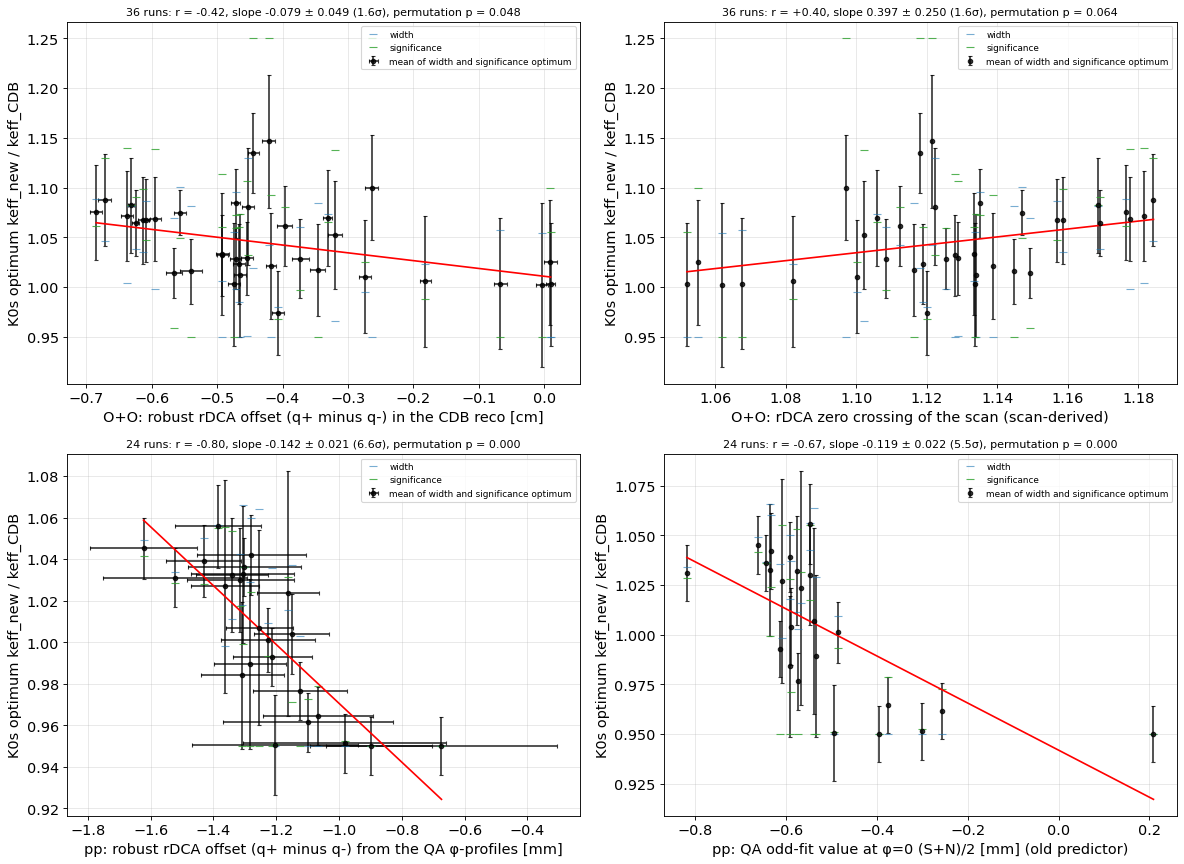

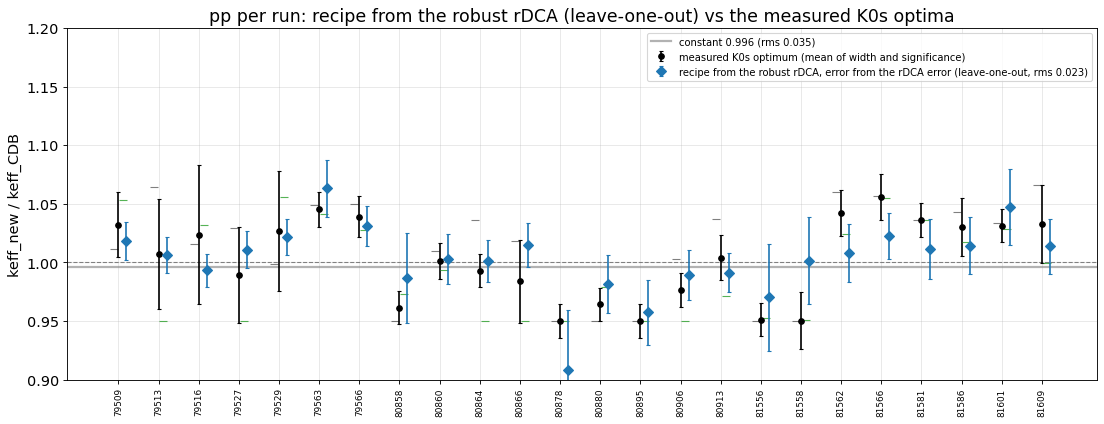

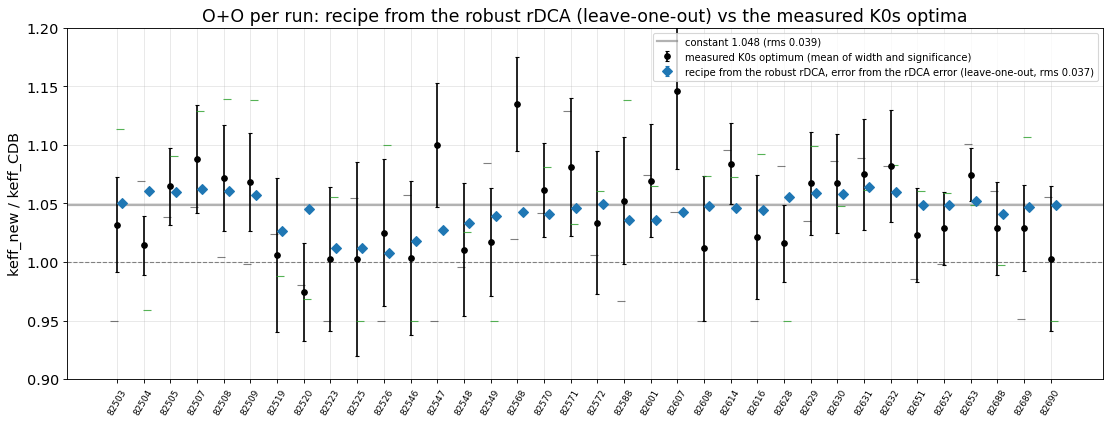

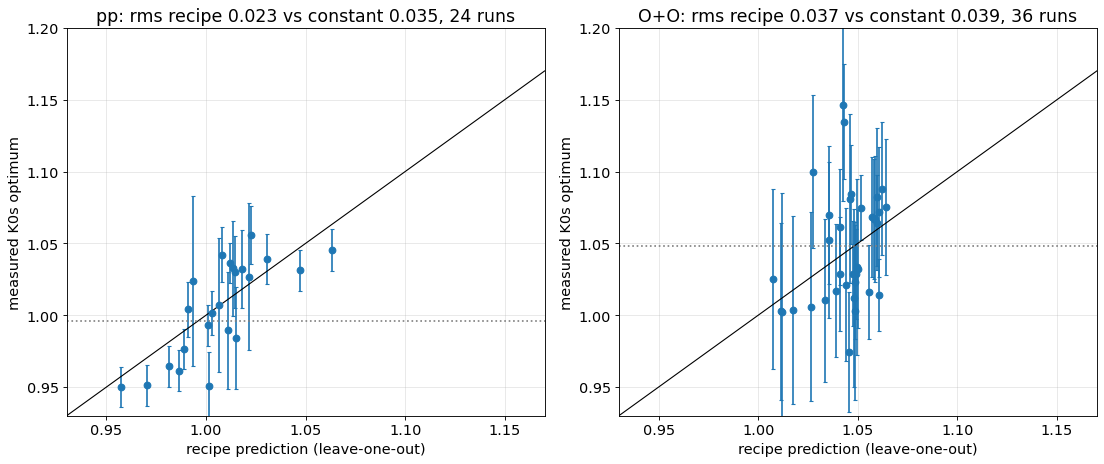

pp:
  constant                         LOO rms 0.0351  weighted chi2/n 2.65
  GEM current                      LOO rms 0.0302  weighted chi2/n 1.78
  ln(N+/N-)                        LOO rms 0.0250  weighted chi2/n 1.31
  robust rDCA                      LOO rms 0.0231  weighted chi2/n 1.02
  robust rDCA + GEM current        LOO rms 0.0225  weighted chi2/n 0.96
  partial correlation (robust rDCA, optimum | GEM current) = -0.71
O+O:
  constant                         LOO rms 0.0387  weighted chi2/n 0.69
  base keff                        LOO rms 0.0393  weighted chi2/n 0.76
  robust rDCA                      LOO rms 0.0366  weighted chi2/n 0.69
  robust rDCA + base keff          LOO rms 0.0374  weighted chi2/n 0.71
  partial correlation (robust rDCA, optimum | base keff) = -0.36


In [9]:
import recal as RC
Hq, c0 = KP.c0_table(G); ppr = KP.pp_robust(KP.qa_cache()); ms = KP.models(G, Ro, Opp, Ooo, Rm, ppr)
for k, nm in (('pp', 'pp'), ('oo', 'O+O')):
    m = ms[k]; print('%s: keff_new/keff_CDB = %.3f %+.3f * [%s]; leave-one-out rms %.3f vs constant %.3f (%d runs, median measurement error %.3f)' % (nm, m['coef'][0], m['coef'][1], m['name'], m['rms_loo'], m['rms_const'], len(m['y']), np.median(m['e'])))
KP.fig_robust(G, Rm, Opp, Ooo, ppr, Rall); plt.show()
KP.fig_strip(ms['pp'], 'pp per run: recipe from the robust rDCA (leave-one-out) vs the measured K0s optima'); plt.show()
KP.fig_strip(ms['oo'], 'O+O per run: recipe from the robust rDCA (leave-one-out) vs the measured K0s optima', rot=60); plt.show()
KP.fig_scatter(ms); plt.show()
# does it just follow the GEM current / base keff? leave-one-out rms of alternative predictors
m = ms['pp']; runs = m['runs']; I = G.I.loc[runs].values; lnr = G.lnr.loc[runs].values; odd = ppr.odd.loc[runs].values; y, e = m['y'], m['e']; print('pp:')
for nm, X in (('constant', np.empty((len(y), 0))), ('GEM current', I[:, None]), ('ln(N+/N-)', lnr[:, None]), ('robust rDCA', odd[:, None]), ('robust rDCA + GEM current', np.c_[odd, I])): RC.report('  ' + nm, X, y, e)
res = lambda a, x: a - np.polyval(np.polyfit(x, a, 1), x)
print('  partial correlation (robust rDCA, optimum | GEM current) = %.2f' % np.corrcoef(res(odd, I), res(y, I))[0, 1])
base = pd.read_csv('/home/yoren/sphenix_remote/soft/macros/TpcProduction/keffscan_base_table.csv').set_index('run'); mo = ms['oo']; r2 = mo['runs']; k2 = base.loc[r2, ['baseS', 'baseN']].mean(axis=1).values; o2 = mo['X'][:, 0]; y2, e2 = mo['y'], mo['e']; print('O+O:')
for nm, X in (('constant', np.empty((len(y2), 0))), ('base keff', k2[:, None]), ('robust rDCA', o2[:, None]), ('robust rDCA + base keff', np.c_[o2, k2])): RC.report('  ' + nm, X, y2, e2)
print('  partial correlation (robust rDCA, optimum | base keff) = %.2f' % np.corrcoef(res(o2, k2), res(y2, k2))[0, 1])

## G2. pp: rDCA, charge balance and K0s side by side

Top to bottom: GEM current; South/North rDCA offset (raw) and the half-difference residual after the trend vs GEM current is removed; ln(N+/N−) raw and residual (green band = range of the residuals of the 8 calibration runs); predictions and measured K0s optima. Yellow = runs flagged by the QA rules; * = calibration run. The second figure shows the observables and the optima against the GEM current, with the quadratic trend that defines the residuals. Then one panel set per run where the observables and the K0s disagree.

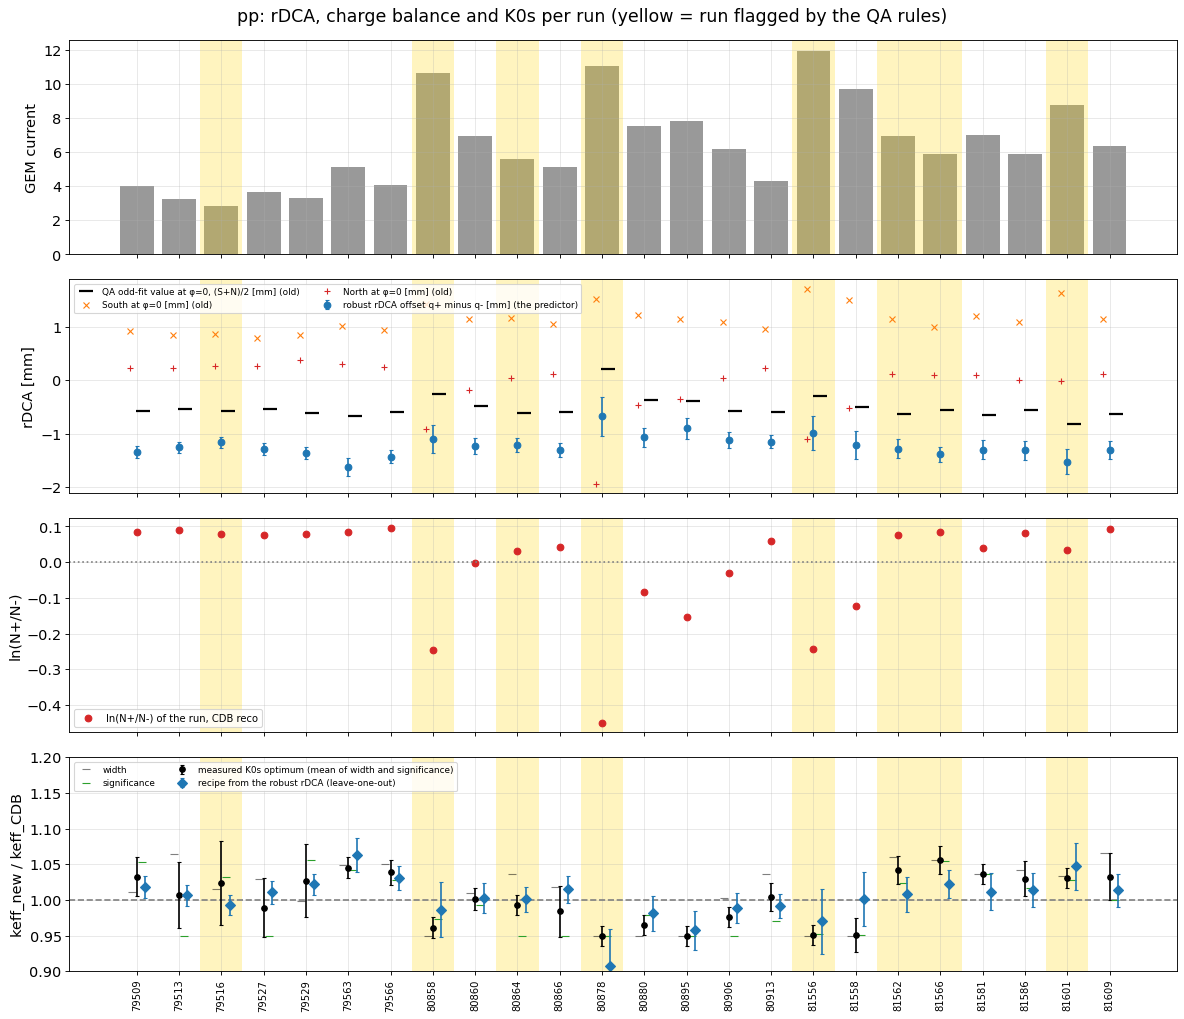

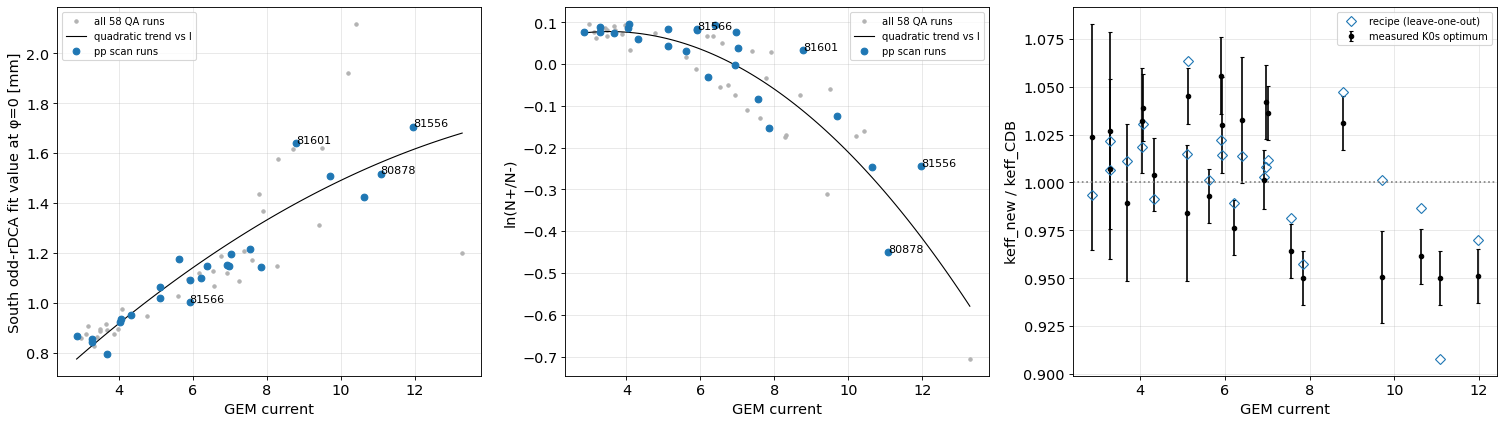

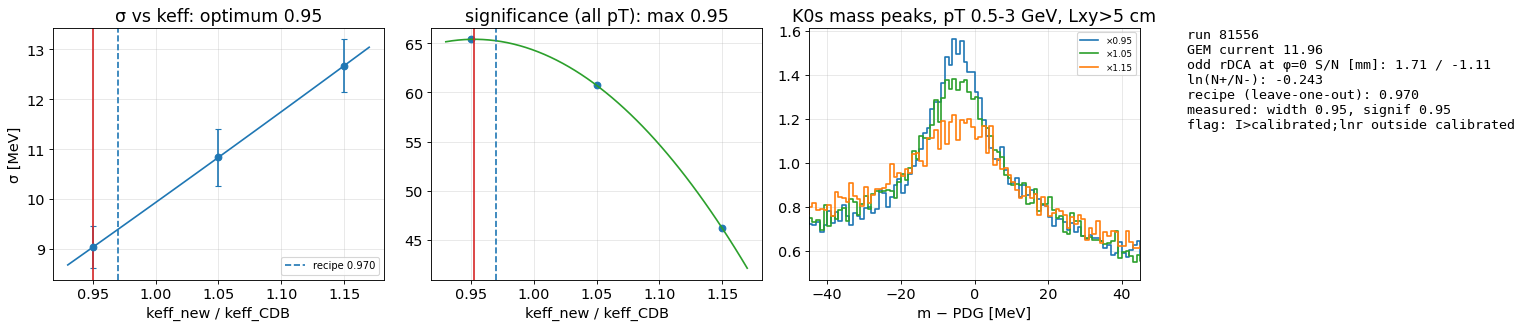

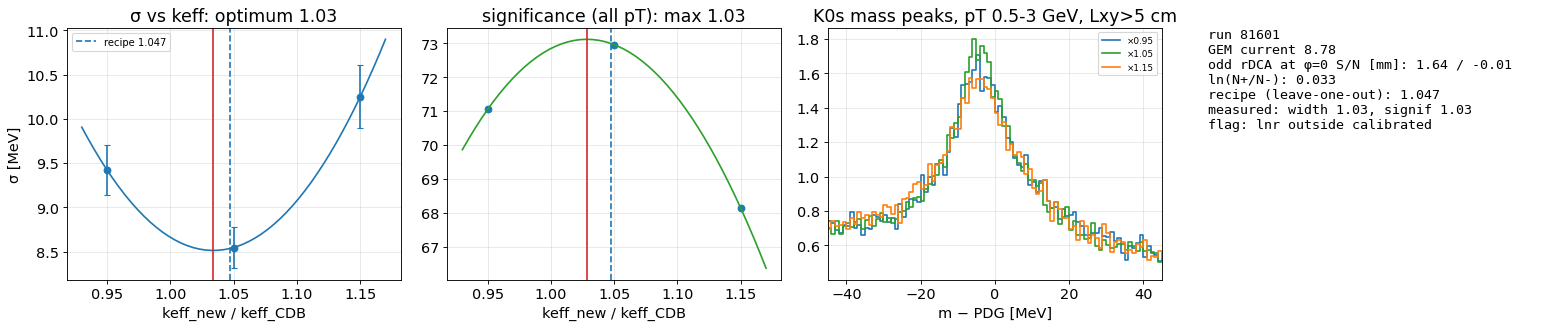

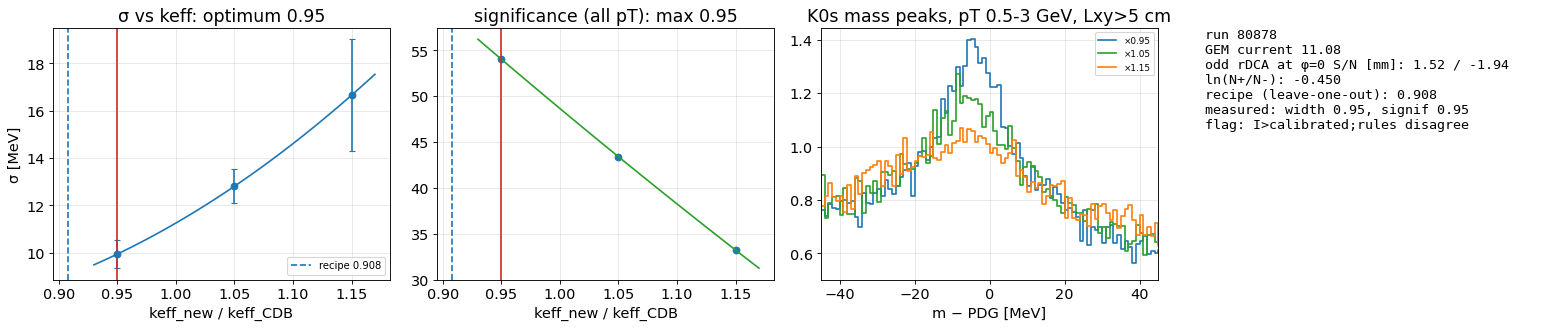

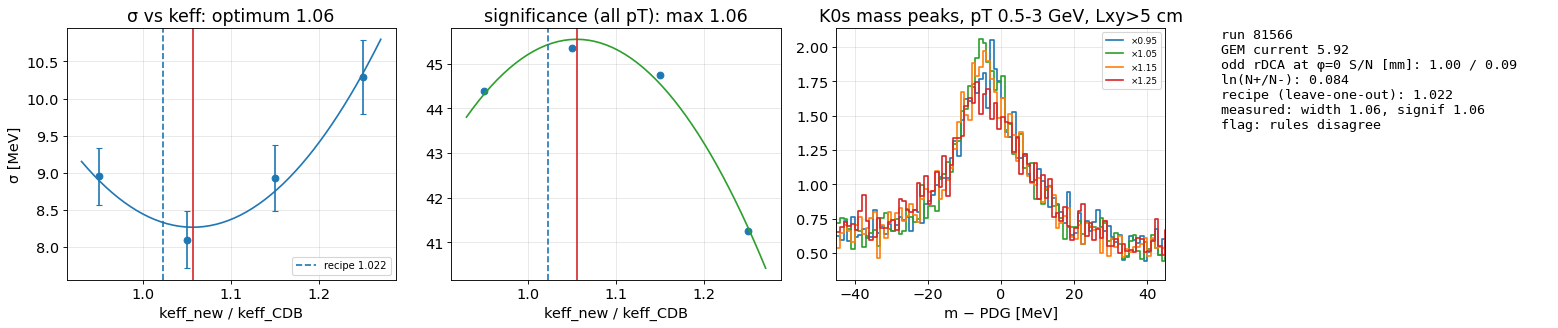

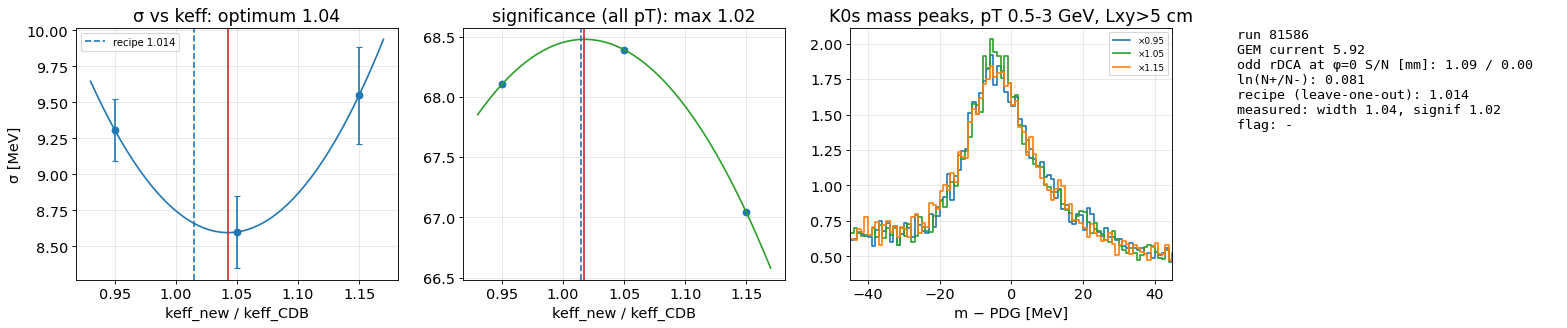

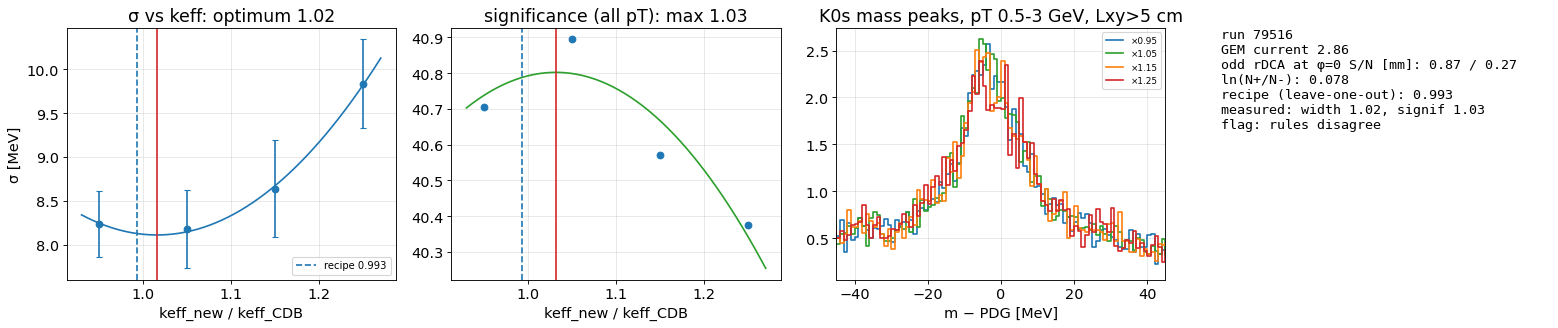

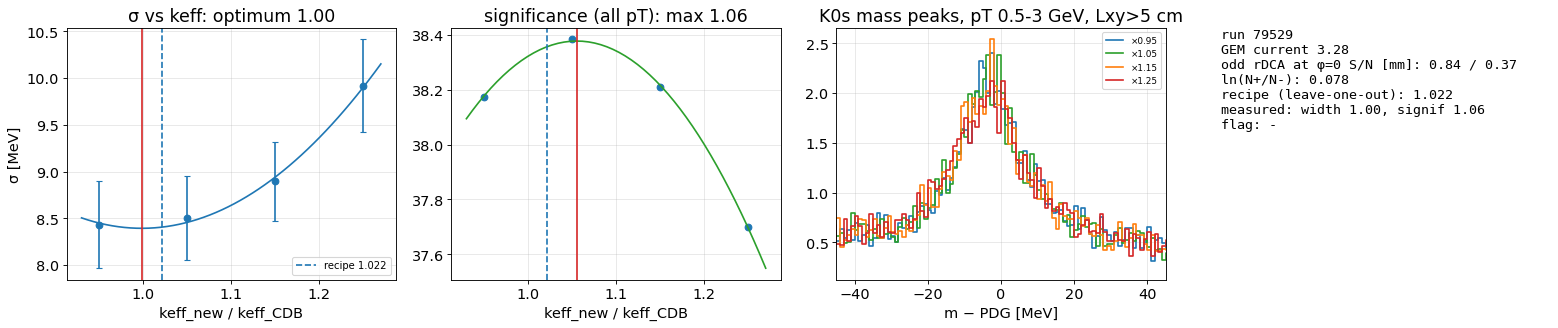

,I,south,north,lnr,half,odd,odd_e,pred,pred_e,sig,Z,opt,opt_e,flag
run,,,,,,,,,,,,,,
79509,4.031,0.922,0.228,0.086,-0.575,-1.341,0.113,1.018,0.016,1.011,1.053,1.032,0.027,
79513,3.282,0.855,0.223,0.090,-0.539,-1.253,0.107,1.006,0.015,1.064,0.950,1.007,0.047,
79516,2.859,0.867,0.266,0.078,-0.567,-1.163,0.100,0.993,0.014,1.016,1.032,1.024,0.059,rules disagree
79527,3.675,0.794,0.272,0.075,-0.533,-1.283,0.114,1.011,0.016,1.029,0.950,0.989,0.041,
79529,3.283,0.843,0.372,0.078,-0.608,-1.362,0.108,1.022,0.015,0.998,1.055,1.027,0.051,
79563,5.119,1.019,0.303,0.083,-0.661,-1.623,0.170,1.063,0.024,1.049,1.041,1.045,0.015,
79566,4.057,0.935,0.245,0.095,-0.590,-1.431,0.120,1.031,0.017,1.050,1.028,1.039,0.017,
80858,10.634,1.426,-0.913,-0.245,-0.256,-1.100,0.270,0.986,0.038,0.950,0.973,0.961,0.014,I>calibrated
80860,6.928,1.151,-0.181,-0.002,-0.485,-1.227,0.150,1.003,0.021,1.009,0.993,1.001,0.015,


In [10]:
tab = KP.pp_table(G, ms['pp'], ppr)
KP.fig_pp_overview(tab); plt.show()
KP.fig_vs_current(G, tab); plt.show()
for r in (81556, 81601, 80878, 81566, 81586, 79516, 79529): KP.fig_inspect(r, tab, pp, zpp); plt.show()
display(tab.round(3))

## G3. pp: is the rDCA input trustworthy at high current? (81556)

The QA "rDCA" feature used by the pp recipe is the harmonic fit of the charge-odd rDCA versus φ **evaluated at φ=0** (constant + cos φ + cos 2φ terms), not the constant term. The O+O observable is a φ-averaged robust offset (sine removed), so the two are different quantities. Below: positive and negative rDCA versus φ for 81556 and reference runs, with the QA fit; then the fit quality against GEM current, and how the K0s optima correlate with the constant term versus the φ=0 value.

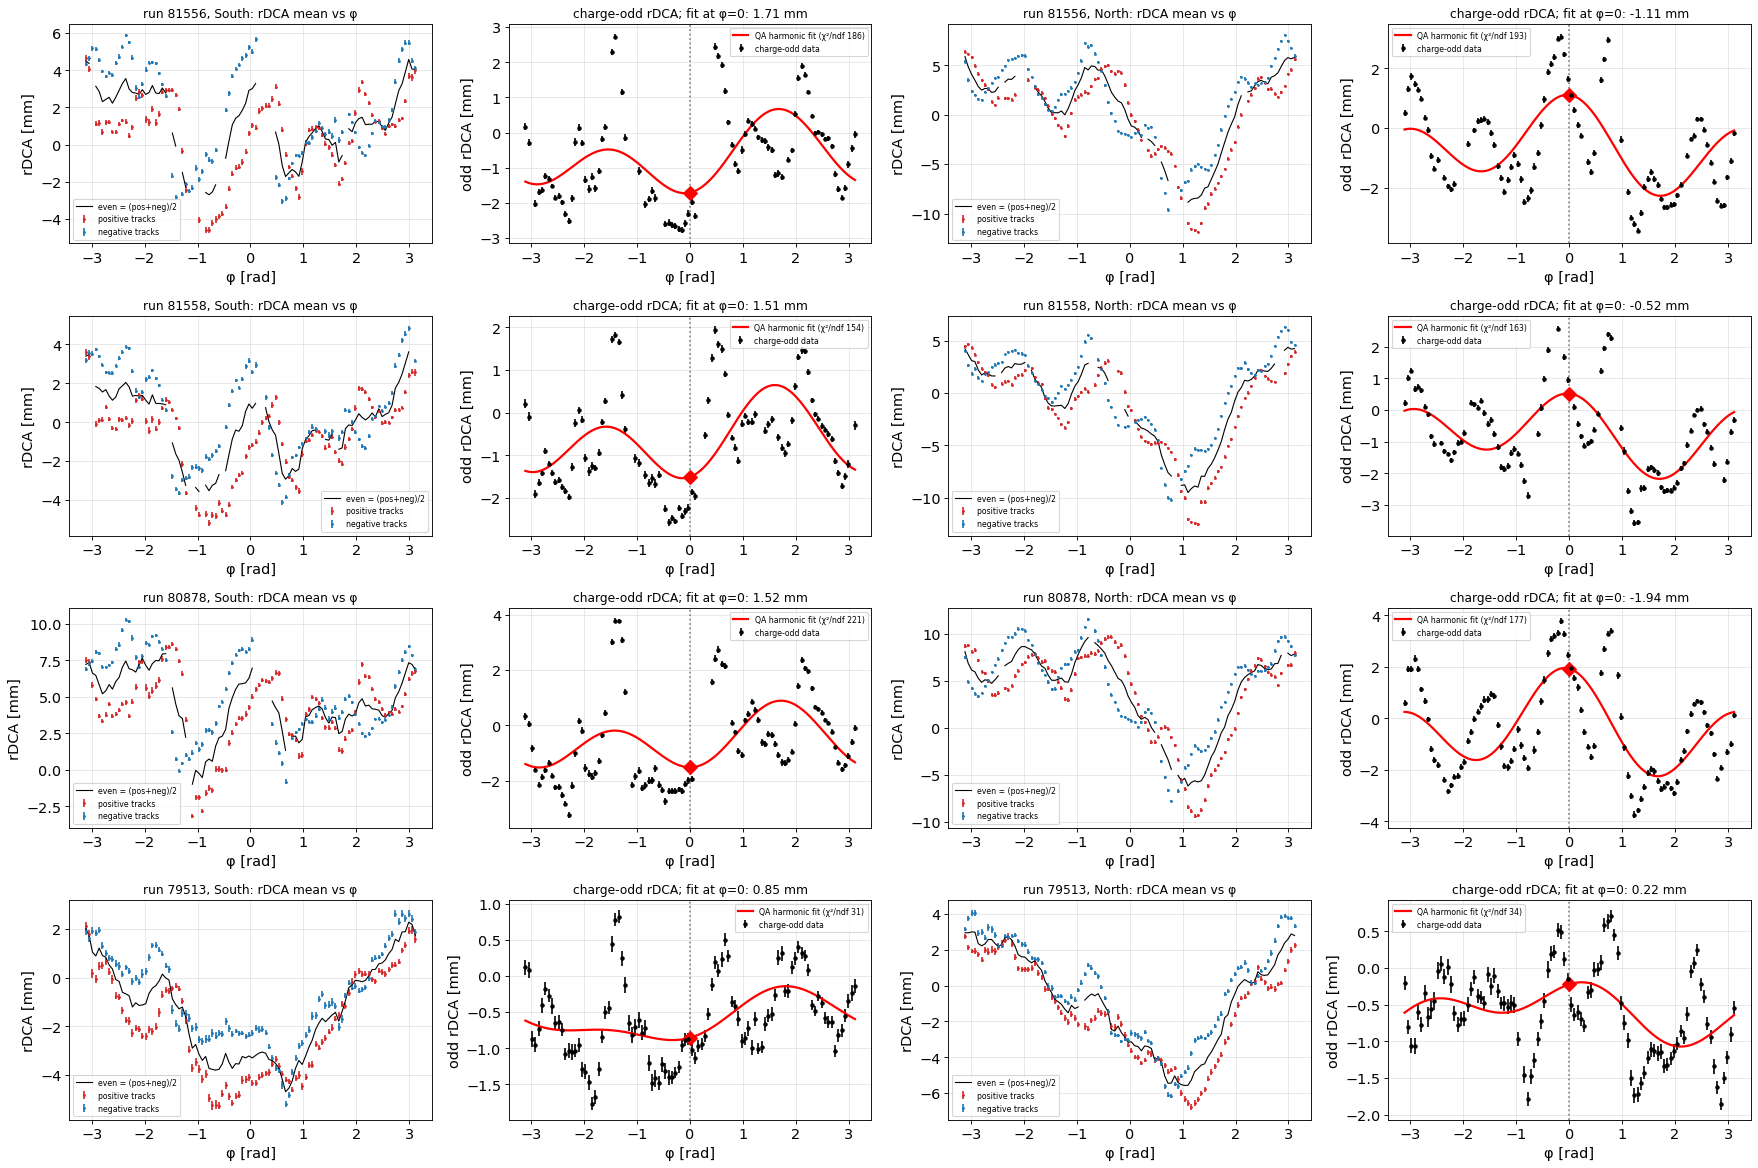

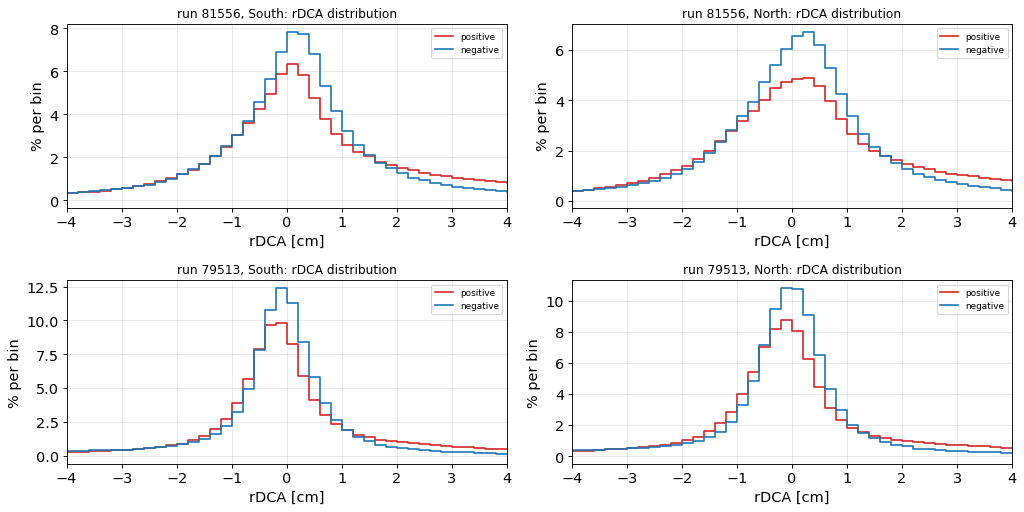

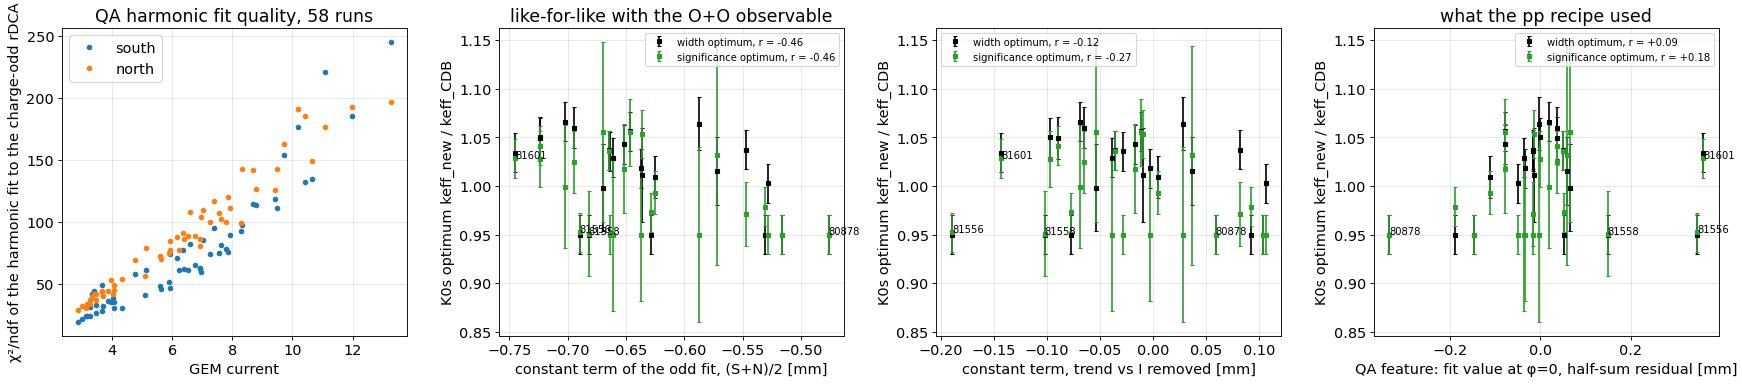

In [11]:
cache = KP.qa_cache()
KP.fig_rdca_phi([81556, 81558, 80878, 79513], cache); plt.show()
KP.fig_rdca_dist([81556, 79513], cache); plt.show()
Hq, c0 = KP.c0_table(G); KP.fig_chi2_and_obs(G, Hq, c0, Opp); plt.show()

## G4. More precise and combined observables

The robust rDCA has an error comparable to its spread between runs (spread/error about 1.3), so its per-run noise limits the prediction. Candidates tried, all with leave-one-out against the K0s optimum:
* **rDCA:** robust offset (unweighted, current), weighted by tracks per φ bin, and with 2nd harmonics in the model (`odd_rob`, `odd_w`, `odd_h2`).
* **Charge balance:** ln(N+/N−) of all tracks and in pT windows 0.5–1, 1–2, 2–4 GeV (`lnr`, `lnr_a/b/c`), and its **pT dependence** `lnr_sl` = ln(N+/N−)[2–4 GeV] − ln(N+/N−)[0.5–1 GeV]. A sagitta error acts differently on the two charges, and the effect grows with pT, so this is a curvature lever. Its error (Poisson, 0.015) is much smaller than its spread between runs (0.2).
* **Combinations** of two predictors (linear, fitted on the other runs). To avoid fooling ourselves with 24 runs, the last line is a nested leave-one-out where the choice of the best predictor or pair is repeated inside every fold.
O+O has the track-level equivalents: ln(N+/N−) at 0.9–1.5 GeV (`lnr_hi_cdb`) and at 0.3–0.6 GeV, and their difference.

pp, 24 runs; measurement error of the optimum: median 0.018, rms 0.027


/home/yoren/.local/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,n,r,spread_over_err,loo_rms,chi2_n
predictor,,,,,
constant,0,NaN,NaN,0.035,NaN
odd_rob,1,-0.795,1.278,0.023,1.016
odd_w,1,-0.760,1.137,0.025,1.189
odd_h2,1,-0.714,1.350,0.026,1.361
lnr,1,0.777,26.541,0.027,1.627
lnr_a,1,0.731,13.147,0.029,1.917
lnr_b,1,0.801,27.354,0.025,1.356
lnr_c,1,0.861,15.465,0.020,0.776
lnr_sl,1,0.870,13.387,0.019,0.684


nested leave-one-out (selection of the best single/pair included): 0.0260
correlation between the two observables: robust rDCA vs lnr_sl  r = -0.84


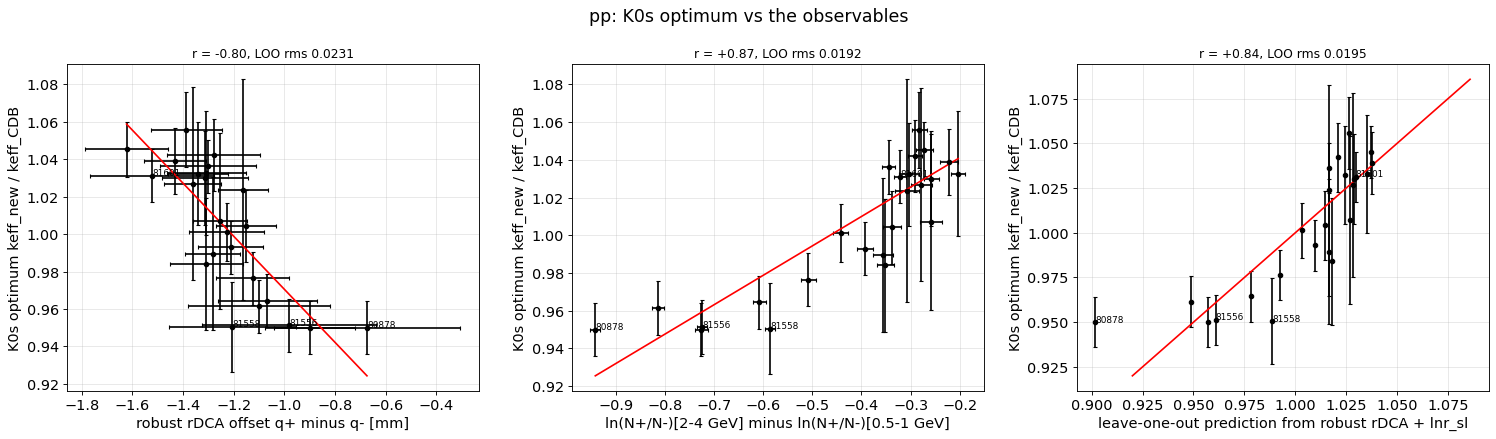

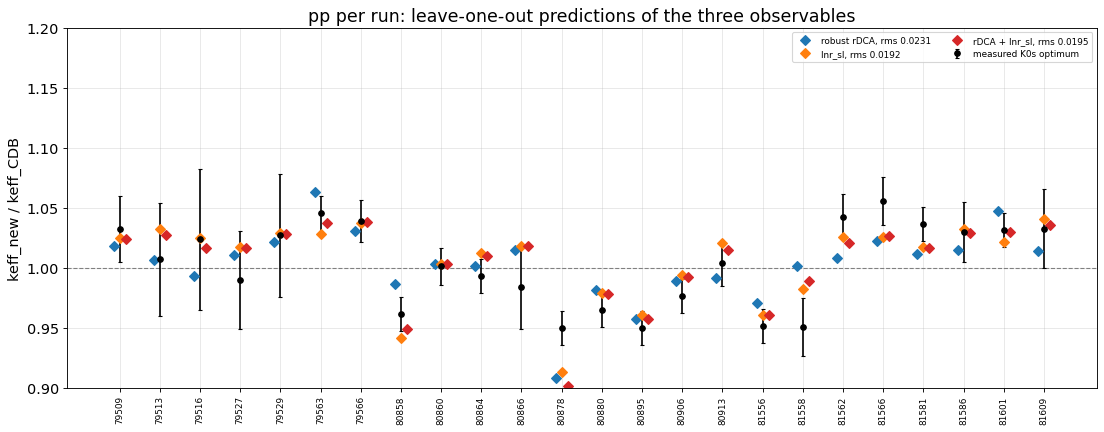

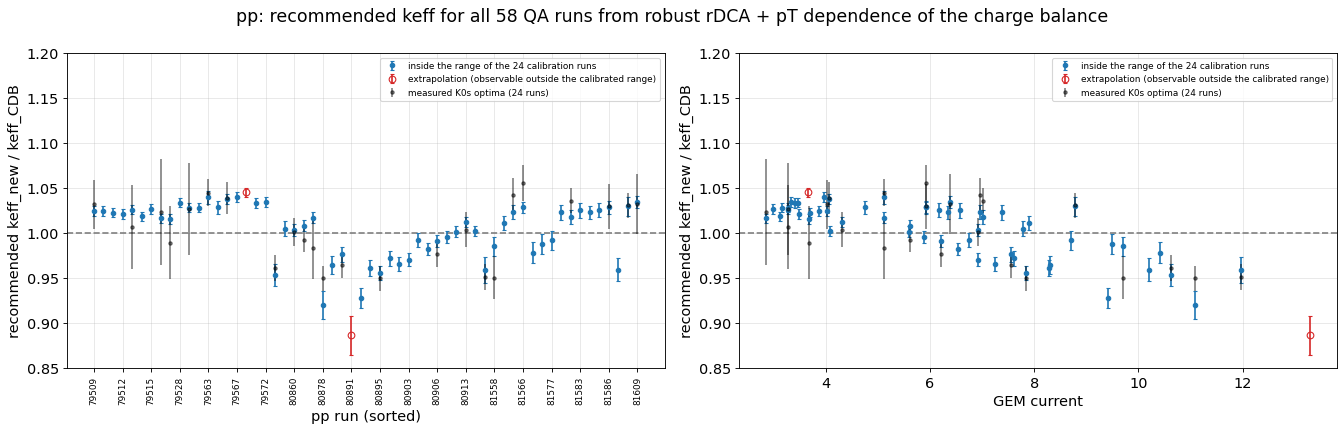

combined pp recipe: keff_new/keff_CDB = 1.004 -0.042 * rDCA_robust[mm] +0.119 * lnr_sl;  2 of 58 runs outside the calibrated range
O+O, 36 runs; measurement error of the optimum: median 0.046


,n,r,spread_over_err,loo_rms,chi2_n
predictor,,,,,
constant,0,NaN,NaN,0.039,NaN
odd0_cdb,1,-0.417,20.389,0.037,0.688
lnr_cdb,1,0.103,2.316,0.041,0.797
lnr_lo_cdb,1,-0.168,NaN,0.040,0.751
lnr_hi_cdb,1,0.204,NaN,0.040,0.771
lnr_sl,1,0.240,NaN,0.039,0.746
odd_slope_cdb,1,0.076,NaN,0.042,0.790
odd0_cdb + lnr_hi_cdb,2,0.271,NaN,0.038,0.733
lnr_cdb + lnr_hi_cdb,2,-0.154,NaN,0.041,0.844


correlation between the two observables: robust rDCA vs lnr_sl  r = -0.58


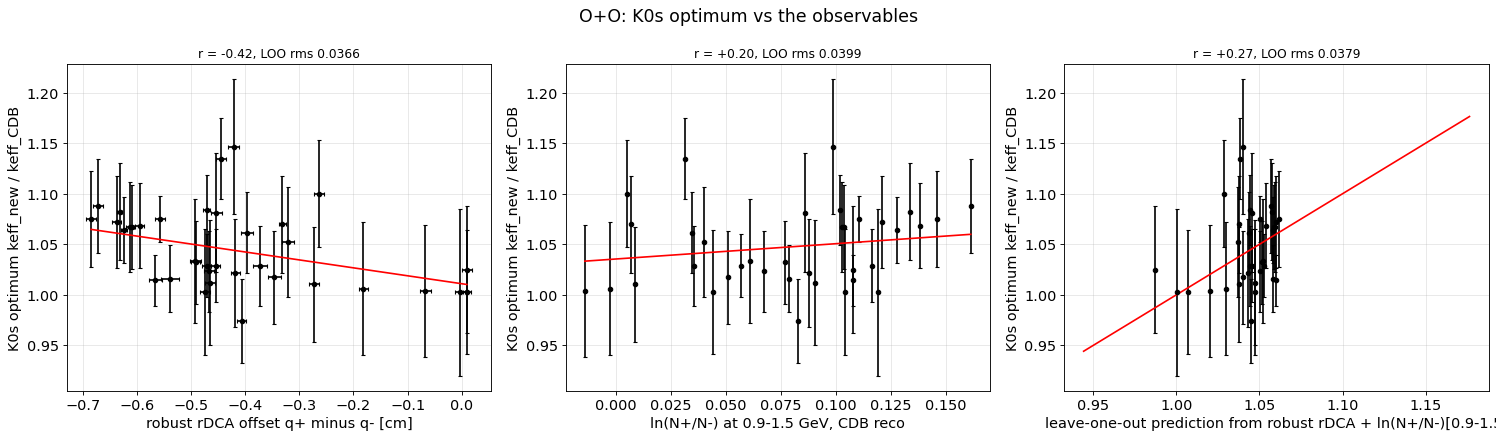

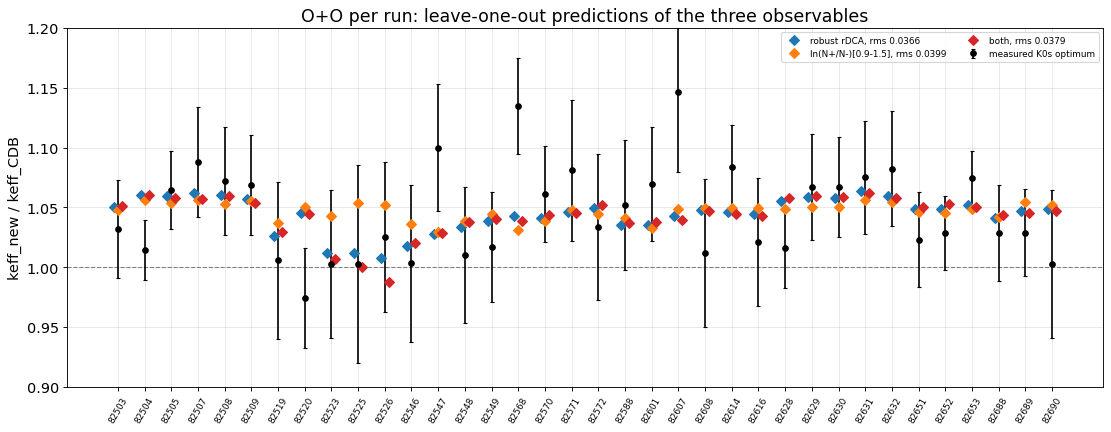

In [12]:
import keffcombo as KB
t, runs, y, e, _ = KB.pp_data(); feats = ['odd_rob', 'odd_w', 'odd_h2', 'lnr', 'lnr_a', 'lnr_b', 'lnr_c', 'lnr_sl', 'I']; combos = [('odd_rob', 'lnr_sl'), ('odd_h2', 'lnr_sl'), ('odd_rob', 'odd_h2'), ('lnr_b', 'lnr_c')]
print('pp, %d runs; measurement error of the optimum: median %.3f, rms %.3f' % (len(y), np.median(e), np.sqrt(np.mean(e**2)))); display(KB.table(t, runs, y, e, feats, combos).round(3))
print('nested leave-one-out (selection of the best single/pair included): %.4f' % KB.nested(t, runs, y, e, ['odd_rob', 'odd_h2', 'lnr', 'lnr_sl', 'lnr_b', 'I']))
print('correlation between the two observables: robust rDCA vs lnr_sl  r = %.2f' % np.corrcoef(t.loc[runs, 'odd_rob'], t.loc[runs, 'lnr_sl'])[0, 1])
KB.fig_scatter3(t, runs, y, e, [(('odd_rob',), 'robust rDCA offset q+ minus q- [mm]'), (('lnr_sl',), 'ln(N+/N-)[2-4 GeV] minus ln(N+/N-)[0.5-1 GeV]'), (('odd_rob', 'lnr_sl'), 'robust rDCA + lnr_sl')], 'pp: K0s optimum vs the observables'); plt.show()
P = lambda cs: RC.loo(t.loc[runs, list(cs)].values, y, e)
KB.fig_strip_multi(runs, y, e, [('robust rDCA', P(['odd_rob']), 'C0', -.15), ('lnr_sl', P(['lnr_sl']), 'C1', 0.0), ('rDCA + lnr_sl', P(['odd_rob', 'lnr_sl']), 'C3', .15)], 'pp per run: leave-one-out predictions of the three observables'); plt.show()
fig, b58, out58 = KB.fig_all58(); plt.show(); print('combined pp recipe: keff_new/keff_CDB = %.3f %+.3f * rDCA_robust[mm] %+.3f * lnr_sl;  %d of %d runs outside the calibrated range' % (b58[0], b58[1], b58[2], (~out58.in_calibrated_range).sum(), len(out58)))
to, runs_o, yo, eo, _ = KB.oo_data(); print('O+O, %d runs; measurement error of the optimum: median %.3f' % (len(yo), np.median(eo)))
display(KB.table(to, runs_o, yo, eo, ['odd0_cdb', 'lnr_cdb', 'lnr_lo_cdb', 'lnr_hi_cdb', 'lnr_sl', 'odd_slope_cdb'], [('odd0_cdb', 'lnr_hi_cdb'), ('lnr_cdb', 'lnr_hi_cdb')]).round(3))
print('correlation between the two observables: robust rDCA vs lnr_sl  r = %.2f' % np.corrcoef(to.loc[runs_o, 'odd0_cdb'], to.loc[runs_o, 'lnr_sl'])[0, 1])
KB.fig_scatter3(to, runs_o, yo, eo, [(('odd0_cdb',), 'robust rDCA offset q+ minus q- [cm]'), (('lnr_hi_cdb',), 'ln(N+/N-) at 0.9-1.5 GeV, CDB reco'), (('odd0_cdb', 'lnr_hi_cdb'), 'robust rDCA + ln(N+/N-)[0.9-1.5]')], 'O+O: K0s optimum vs the observables'); plt.show()
Q = lambda cs: RC.loo(to.loc[runs_o, list(cs)].values, yo, eo)
KB.fig_strip_multi(runs_o, yo, eo, [('robust rDCA', Q(['odd0_cdb']), 'C0', -.15), ('ln(N+/N-)[0.9-1.5]', Q(['lnr_hi_cdb']), 'C1', 0.0), ('both', Q(['odd0_cdb', 'lnr_hi_cdb']), 'C3', .15)], 'O+O per run: leave-one-out predictions of the three observables', rot=60); plt.show()

### What to take from G4

* **pp.** The pT dependence of the charge balance is the most precise observable (spread/error 13 against 1.3 for the rDCA) and the best single predictor: r = +0.87 with the K0s optimum, leave-one-out rms 0.019 against 0.035 for a constant, χ²/n 0.68. Robust rDCA alone gives r = −0.80, rms 0.023. The two are strongly correlated with each other (r = −0.84); the combination gains almost nothing (rms 0.019; nested leave-one-out, which repeats the choice of predictor in every fold, 0.026) because every good predictor is already near the K0s noise floor (rms error of the optimum 0.027). The combined recipe is the safest choice: it keeps both independent measurements and has a smaller propagated error than the rDCA alone.
* **O+O.** With the adopted selection the precise rDCA offset is the better predictor: r = −0.42, leave-one-out rms 0.0366 against 0.0387 for a constant. The charge balance is weak (r = +0.10 to +0.24 depending on the definition) and combinations do not improve on the rDCA. The target error (median 0.046) is larger than the spread of the optima, so even a constant fits (χ²/n 0.69); the O+O per-run optima cannot yet discriminate between predictors.
* The recommended keff for all 58 pp QA runs is in `keff_recommendation_pp_58runs.csv`, with errors and a flag for runs outside the calibrated range.

### Is the charge balance doing all the work? Partial correlations

The rDCA offset and the charge balance are strongly correlated with each other, and the balance also follows the GEM current, so either could carry a common cause that is not keff (for example a physical charge asymmetry of the track sample, or the composition of the positive and negative tracks). Partial correlations with the K0s optimum, controlling for the other variables:

In [13]:
def pc(y_, x_, z_):
    Z = np.column_stack([np.ones(len(y_))] + [np.atleast_1d(c) for c in z_]); r_ = lambda a: a - Z@np.linalg.lstsq(Z, a, rcond=None)[0]; return np.corrcoef(r_(y_), r_(x_))[0, 1]
T_ = t.loc[runs]; o_, s_, I_ = T_.odd_rob.values, T_.lnr_sl.values, T_.I.values
print('pp (%d runs): corr(rDCA, lnr_sl) = %.2f, corr(lnr_sl, GEM current) = %.2f, corr(rDCA, GEM current) = %.2f' % (len(y), np.corrcoef(o_, s_)[0, 1], np.corrcoef(s_, I_)[0, 1], np.corrcoef(o_, I_)[0, 1]))
for nm, a_, z_ in (('rDCA | lnr_sl', o_, [s_]), ('lnr_sl | rDCA', s_, [o_]), ('rDCA | lnr_sl, GEM current', o_, [s_, I_]), ('lnr_sl | rDCA, GEM current', s_, [o_, I_]), ('rDCA | GEM current', o_, [I_]), ('lnr_sl | GEM current', s_, [I_])): print('   partial corr(optimum, %-28s) = %+.2f' % (nm, pc(y, a_, z_)))
To_ = to.loc[runs_o]; oo_, so_ = To_.odd0_cdb.values, To_.lnr_hi_cdb.values; bk = pd.read_csv('/home/yoren/sphenix_remote/soft/macros/TpcProduction/keffscan_base_table.csv').set_index('run').loc[runs_o, ['baseS', 'baseN']].mean(axis=1).values
print('O+O (%d runs): corr(rDCA, lnr_hi) = %.2f, corr(lnr_hi, base keff) = %.2f' % (len(yo), np.corrcoef(oo_, so_)[0, 1], np.corrcoef(so_, bk)[0, 1]))
for nm, a_, z_ in (('rDCA | lnr_hi', oo_, [so_]), ('lnr_hi | rDCA', so_, [oo_]), ('lnr_hi | base keff', so_, [bk])): print('   partial corr(optimum, %-28s) = %+.2f' % (nm, pc(yo, a_, z_)))

pp (24 runs): corr(rDCA, lnr_sl) = -0.84, corr(lnr_sl, GEM current) = -0.79, corr(rDCA, GEM current) = 0.53
   partial corr(optimum, rDCA | lnr_sl               ) = -0.25
   partial corr(optimum, lnr_sl | rDCA               ) = +0.62
   partial corr(optimum, rDCA | lnr_sl, GEM current  ) = -0.14
   partial corr(optimum, lnr_sl | rDCA, GEM current  ) = +0.58
   partial corr(optimum, rDCA | GEM current          ) = -0.71
   partial corr(optimum, lnr_sl | GEM current        ) = +0.81
O+O (36 runs): corr(rDCA, lnr_hi) = -0.58, corr(lnr_hi, base keff) = -0.37
   partial corr(optimum, rDCA | lnr_hi               ) = -0.37
   partial corr(optimum, lnr_hi | rDCA               ) = -0.05
   partial corr(optimum, lnr_hi | base keff          ) = +0.32


**Reading.** In pp, once the charge balance is known the rDCA adds little (partial correlation −0.25; −0.14 also controlling for the GEM current), while the balance keeps its power (+0.62; +0.58 with the current; +0.81 at fixed current alone). In O+O it is the other way round: the rDCA keeps −0.37 at fixed balance and the balance adds nothing (−0.05; +0.32 at fixed base keff). So in pp the larger weight on the charge balance is not an accident of the fit, but it makes the combined predictor mostly a charge-balance predictor. Whether the balance reflects keff or a physical charge asymmetry that follows the run conditions cannot be settled from these numbers; a charge-symmetric probe is needed, e.g. the π+/π− ratio of the K0s daughters.

### Is the charge balance robust? Variants and a reliability-weighted combination

The run-to-run baseline of the charge balance is not zero (p̄/p, secondaries, dead maps); the recipe is a straight line with an intercept, so only the change from run to run enters. To see whether the balance is robust, it is computed in several ways that react differently to dead maps and acceptance: all tracks, the median over φ bins or η bins instead of the integral, the high-pT value, and its pT dependence. For O+O each side separately. The two single-observable predictions are also combined with weights ∝ 1/rms², which has no fitted parameters, unlike the two-variable regression that overfits with noisy inputs.

,r,loo_rms
pp_observable,,
lnr_sl,0.870,0.019
lnr_c,0.861,0.020
lnr,0.777,0.027
lnr_phi_med,0.808,0.025
lnr_phi_mean,0.805,0.025
lnr_eta_med,0.793,0.026
lnr_eta_mean,0.805,0.025
odd_rob,-0.795,0.023


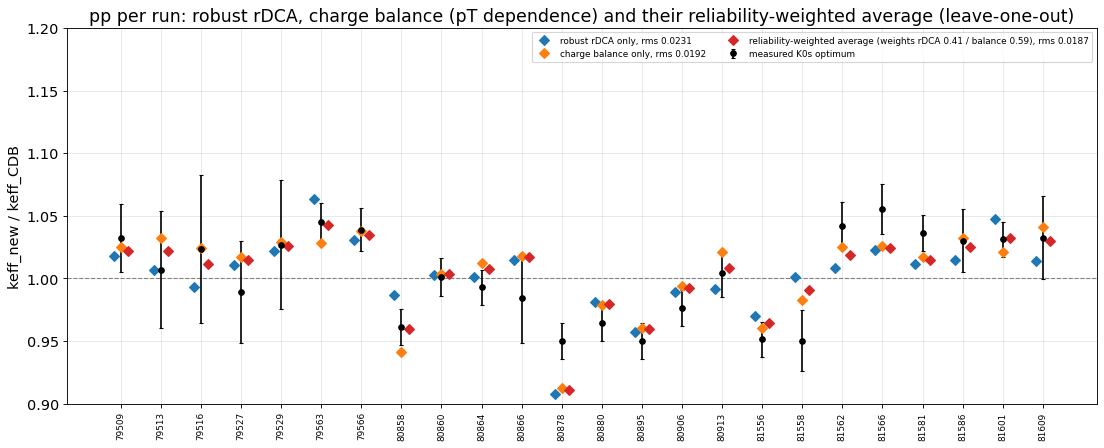

pp: weighted average rms 0.0187 (regression on both 0.0195, balance alone 0.0192, rDCA alone 0.0231, constant 0.0351)
O+O charge balance per side (ln(N+/N-) at 0.9-1.5 GeV) against the run optimum:
   South: r = +0.14, leave-one-out rms 0.0405
   North: r = +0.20, leave-one-out rms 0.0397


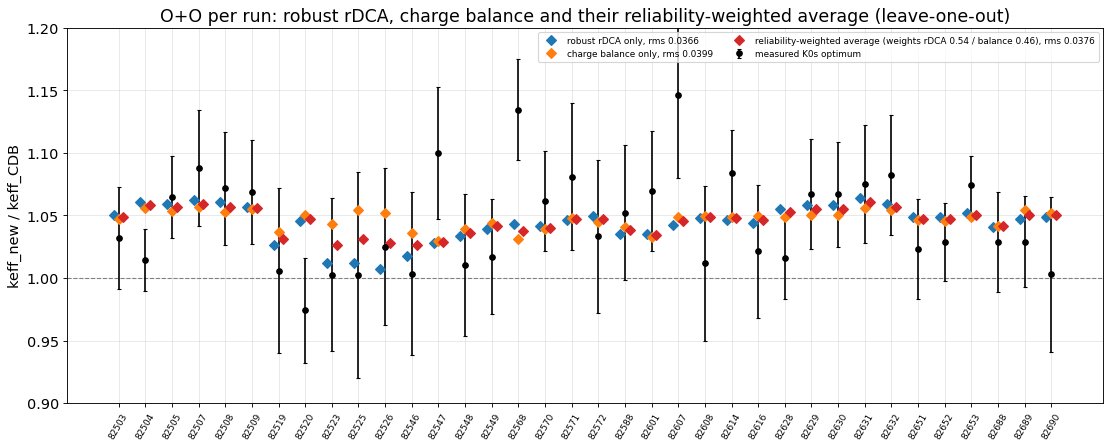

O+O: weighted average rms 0.0376 (regression on both 0.0379, balance alone 0.0399, rDCA alone 0.0366, constant 0.0387)


In [14]:
tv = t.join(KB.pp_balance_variants()); rows = []
for f in ['lnr_sl', 'lnr_c', 'lnr', 'lnr_phi_med', 'lnr_phi_mean', 'lnr_eta_med', 'lnr_eta_mean', 'odd_rob']:
    xx = tv.loc[runs, f].values; pp_ = RC.loo(xx[:, None], y, e); rows.append(dict(pp_observable=f, r=np.corrcoef(xx, y)[0, 1], loo_rms=np.sqrt(np.mean((y - pp_)**2))))
display(pd.DataFrame(rows).set_index('pp_observable').round(3))
pr_, pb_ = RC.loo(t.loc[runs, ['odd_rob']].values, y, e), RC.loo(t.loc[runs, ['lnr_sl']].values, y, e)
fig, pw_, w_ = KB.fig_wcomb(runs, y, e, pr_, pb_, 'pp per run: robust rDCA, charge balance (pT dependence) and their reliability-weighted average (leave-one-out)'); plt.show()
print('pp: weighted average rms %.4f (regression on both %.4f, balance alone %.4f, rDCA alone %.4f, constant %.4f)' % (np.sqrt(np.mean((y - pw_)**2)), np.sqrt(np.mean((y - RC.loo(t.loc[runs, ['odd_rob', 'lnr_sl']].values, y, e))**2)), np.sqrt(np.mean((y - pb_)**2)), np.sqrt(np.mean((y - pr_)**2)), np.sqrt(np.mean((y - np.average(y, weights=1/e**2))**2))))
Rs = pd.read_csv(KP.V + 'fit_obs_perrun.csv'); print('O+O charge balance per side (ln(N+/N-) at 0.9-1.5 GeV) against the run optimum:')
for sd, nm in ((0, 'South'), (1, 'North')):
    g_ = Rs[Rs.side == sd].set_index('run'); xx = g_.loc[runs_o, 'lnr_hi_cdb'].values; pq = RC.loo(xx[:, None], yo, eo); print('   %s: r = %+.2f, leave-one-out rms %.4f' % (nm, np.corrcoef(xx, yo)[0, 1], np.sqrt(np.mean((yo - pq)**2))))
qr_, qb_ = RC.loo(to.loc[runs_o, ['odd0_cdb']].values, yo, eo), RC.loo(to.loc[runs_o, ['lnr_hi_cdb']].values, yo, eo)
fig, qw_, wo_ = KB.fig_wcomb(runs_o, yo, eo, qr_, qb_, 'O+O per run: robust rDCA, charge balance and their reliability-weighted average (leave-one-out)', rot=60); plt.show()
print('O+O: weighted average rms %.4f (regression on both %.4f, balance alone %.4f, rDCA alone %.4f, constant %.4f)' % (np.sqrt(np.mean((yo - qw_)**2)), np.sqrt(np.mean((yo - RC.loo(to.loc[runs_o, ['odd0_cdb', 'lnr_hi_cdb']].values, yo, eo))**2)), np.sqrt(np.mean((yo - qb_)**2)), np.sqrt(np.mean((yo - qr_)**2)), np.sqrt(np.mean((yo - np.average(yo, weights=1/eo**2))**2))))

**Reading.** In pp every way of building the balance (integral, φ-median, η-median, high pT, pT dependence) correlates with the K0s optimum at r = +0.78 to +0.87, so it does not depend on one dead-map-sensitive definition. The reliability-weighted average has the smallest leave-one-out rms, 0.0187, below the balance alone (0.0192), the two-variable regression (0.0195) and the rDCA alone (0.0231). In O+O the balance is weak on both sides (r = +0.14 South, +0.20 North); the weighted average (rms 0.0376) is no better than the rDCA alone (0.0366), and all are within noise of a constant (0.0387).

In [15]:
# per-run tables (also saved as csv)
for k, nm in (('oo', 'oo'), ('pp', 'pp')):
    m = ms[k]; t = pd.DataFrame({'run': m['runs'], 'observable': m['X'][:, 0], 'recipe_all_runs': m['pred'], 'recipe_loo': m['loo'], 'width_opt': m['ysig'], 'signif_opt': m['yz'], 'opt_mean': m['y'], 'opt_err': m['e']})
    t.round(3).to_csv(KP.V + 'keff_recommendation_%s.csv' % nm, index=False); print(nm, m['name']); display(t.round(3).head(8))

oo robust rDCA offset q+ minus q- in the CDB reco [cm]


,run,observable,recipe_all_runs,recipe_loo,width_opt,signif_opt,opt_mean,opt_err
0,82503,-0.492,1.050,1.050,0.950,1.114,1.032,0.041
1,82504,-0.566,1.055,1.061,1.069,0.959,1.014,0.025
2,82505,-0.624,1.060,1.060,1.039,1.090,1.065,0.033
3,82507,-0.672,1.064,1.062,1.047,1.129,1.088,0.046
4,82508,-0.638,1.061,1.060,1.004,1.139,1.072,0.045
5,82509,-0.595,1.058,1.057,0.999,1.138,1.069,0.042
6,82519,-0.182,1.025,1.026,1.024,0.988,1.006,0.066
7,82520,-0.407,1.043,1.045,0.980,0.968,0.974,0.042


pp robust rDCA offset q+ minus q- from the QA φ-profiles [mm]


,run,observable,recipe_all_runs,recipe_loo,width_opt,signif_opt,opt_mean,opt_err
0,79509,-1.341,1.019,1.018,1.011,1.053,1.032,0.027
1,79513,-1.253,1.006,1.006,1.064,0.950,1.007,0.047
2,79516,-1.163,0.994,0.993,1.016,1.032,1.024,0.059
3,79527,-1.283,1.011,1.011,1.029,0.950,0.989,0.041
4,79529,-1.362,1.022,1.022,0.998,1.055,1.027,0.051
5,79563,-1.623,1.059,1.063,1.049,1.041,1.045,0.015
6,79566,-1.431,1.032,1.031,1.050,1.028,1.039,0.017
7,80858,-1.100,0.985,0.986,0.950,0.973,0.961,0.014


## H. Recipe and what is still open

K0s selection for the optimum: pT 0.5–3 GeV, decay length Lxy > 5 cm, sailor cut (section S).

1. **Measure** the robust rDCA offset q+ minus q− of the run in the CDB reco: φ-averaged per charge with the sine removed (O+O: from the tracks; pp: from the QA φ-profiles, section G), and for pp also the pT dependence of ln(N+/N−).
2. **pp:** keff_new/keff_CDB = 0.829 − 0.142 · rDCA_robust[mm] (leave-one-out rms 0.023 against 0.035 for a constant; partial correlation at fixed GEM current −0.71). With the charge-balance pT dependence `lnr_sl` (G4): 1.004 − 0.042 · rDCA_robust[mm] + 0.119 · lnr_sl, and the reliability-weighted average of the two single recipes has the smallest rms, 0.0187. The high-current runs 80878, 80895, 81556 and 80858 come out at 0.92–0.96, where their K0s optima are.
3. **O+O:** the K0s optimum follows the same sign (more negative offset, higher optimum): r = −0.42 with the CDB-reco offset (permutation p = 0.048), r = +0.40 with the rDCA zero crossing of the scan (p = 0.064). The leave-one-out recipe from the offset has rms 0.0366 against 0.0387 for the constant 1.05: a small gain, within the noise, because the per-run K0s error (median 0.046) exceeds the spread of the optima (0.039).
4. **Retired:** the pp recipe from the QA harmonic fit at φ=0 (χ²/ndf up to 245; the trend-subtracted residual carries no information). The pT 1.0–3 GeV K0s selection did not hold in O+O (section S).
5. Typical K0s optima are 1.02 (pp) and 1.04 (O+O) with 6 of 24 pp and 25 of 67 O+O runs at the 0.95 edge, so the gain of a per-run keff over the plain CDB value is a few percent and has to be shown on a large sample.

**Open:** does the MLP map plus a keff correction improve the K0s over the plain CDB reco on a large sample? Next step: three configurations on the same segments and events (CDB, map with CDB keff, map with recipe keff) and a paired comparison per run.